# Spotify Song Popularity — Notebook 1: Data Cleaning and Splitting

IS 507 Midterm Project (version 5). This notebook produces the clean datasets, the data split, and the official baseline used in the midterm report.

## Notebook Outline

| Section | Content | Main outputs | Report reference |
|---|---|---|---|
| 1.1–1.4 | Setup, configuration, storage paths, data download | `CONFIG`, `RAW_PATH` | Table 2 |
| 1.5–1.5b | Raw data overview: size, column types, missing values, songs per year, songs per genre, popularity distribution | `01_raw_overview.png` | Section 4.1 |
| 1.6, 2.1–2.2 | Cleaning log, type conversion, song identity (`song_key`) and first release year (`first_year`) | `02_song_versions.png` | Section 4.2 |
| 2.3 | **Step 1**: year filter (2009–2025) with sensitivity table | `03_year_decision.png` | Section 4.2, Step 1 |
| 2.4 | **Steps 2–4**: missing values, invalid popularity, invalid audio values | `04_audio_ranges.png` | Section 4.2, Steps 2–4 |
| 2.5 | Lyrics cleaning (`lyrics_model_text`) and the 20-word threshold (`has_lyrics`) | `05_newline_diagnosis.png`, `06_lyrics_threshold.png` | Sections 4.1, 4.2 Step 9 |
| 2.5b | **Step 5**: exclusion of non-English lyrics, with `langdetect` validation | `06b_language_filter.png` | Section 4.2, Step 5 |
| 2.6 | **Step 6**: exclusion of zero-popularity records | `07_zero_popularity.png` | Section 4.2, Step 6 |
| 2.7 | **Steps 7–8**: duplicate IDs and merging of song versions | `08_dedupe_rule.png` | Section 4.2, Steps 7–8 |
| 2.8 | Duplicate-lyrics groups (`lyrics_group_id`, SHA-256) | `08b_lyrics_groups.png` | Section 6.2 |
| 2.9 | **Step 9** and the cleaning funnel | `09_cleaning_funnel.png` (Figure 1) | Section 4.2 |
| 2.10 | Stratified 70/15/15 split (era × genre × has lyrics); artist-group and temporal splits for robustness | `10_split_primary_vs_artist.png`, `11_year_genre_by_split.png` | Section 6.2 |
| 2.11 | Leakage checks: duplicate-lyrics groups and artist overlap | `12_artist_overlap.png` | Sections 4.3, 6.2 |
| 2.12 | Official baseline: training-set median | `results/baseline_reference.csv` | Section 6.1 |
| 2.13 | Export of the lyrics dataset (171,096 songs) and the audio dataset (171,510 songs) | `songs_clean.parquet`, `songs_clean_audio.csv` | Table 2 |
| 2.14 | Methodology sanity checks | `results/methodology_sanity_checks.csv` | Section 6.2 |

All figures are saved to `figures/` at 200 dpi. Run the cells in order.

---
# Part 1 — Data Acquisition and Cleaning

## 1.1 Setup

This section loads the required packages and fixes the random seed.

| Package | Purpose |
|---|---|
| `pandas` | Tabular data handling |
| `numpy` | Numerical computation |
| `matplotlib`, `seaborn` | Visualization |
| `json`, `re` | Parsing artist lists; text cleaning with regular expressions |
| `kagglehub` | Dataset download from Kaggle |
| `unicodedata` | Unicode normalization (e.g., full-width / half-width characters, apostrophe variants) |
| `hashlib` | SHA-256 fingerprints of lyrics (`lyrics_group_id`) |
| `scipy.sparse.csgraph` | Connected components of artists linked through identical lyrics (artist-group split) |
| `sklearn ENGLISH_STOP_WORDS` | English stop-word list (language filter) |
| `langdetect` (optional) | Validation of the language-filter rule on a sample |
| `sklearn.metrics.mean_absolute_error` | MAE of the official baseline |

TF-IDF, Ridge, and NLTK are loaded in `02_lyrics_features.ipynb`; this notebook fits no TF-IDF or scaler (verified in 2.14). A fixed random seed makes sampling and random splitting reproducible.

In [ ]:
# [COLAB_ONLY] Run this cell in Colab only
!pip -q install kagglehub langdetect

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 9.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
import os
import re
import json
import time
import hashlib
import unicodedata
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Packages loaded")

Packages loaded


## 1.2 Research Design Parameters (Config)

All research-design decisions are collected in a single configuration so that the full notebook can be re-run with alternative settings for robustness checks.

Parameters are of two types:
- **Theory-driven**: determined by the research question or an external fact, not by inspecting results (to avoid p-hacking and data snooping).
- **Data-driven**: determined from the data distribution using evidence on data quality; never chosen based on test performance.

| Parameter | Setting | Type | Candidates considered | Evidence |
|---|---|---|---|---|
| `YEAR_MIN` / `YEAR_MAX` | 2009 / 2025 | Theory-driven | 2000, 2005, 2009, 2012, 2015 | 2.3 |
| `YEAR_BASIS` | first_year | Theory-driven | version_year, first_year | 2.3 |
| `DROP_ZERO_POPULARITY` | True | Data-driven | True, False | 2.6 |
| `MIN_WORDS` | 20 | Data-driven | 5, 10, 20, 30, 50 | 2.5 (threshold for valid lyrics; songs below it are flagged `has_lyrics = 0`, not removed) |
| `LANG_MIN_EN_STOPWORD_RATIO` | 0.25 | Data-driven | 0.15, 0.20, 0.25, 0.30, 0.35 | 2.5b |
| `LANG_MAX_NON_ASCII_RATIO` | 0.10 | Data-driven | — | 2.5b |
| `DEDUP_KEEP` | max_popularity | Theory-driven + sensitivity | max_popularity, earliest | 2.7 |
| `SPLIT_METHOD` | **random** | Theory-driven (research question) | random (primary), artist_group (robustness), temporal (robustness) | 0.6, 2.10 |
| `STRATIFY_GENRE` | True | Theory-driven | era only, era × genre | 2.10 |
| `ERA_BINS` | 2009 / 2013 / 2017 / 2021 / 2026 | Theory-driven | 3-, 4-, or 5-year bins | 2.10 |
| `TRAIN_RATIO` / `VAL_RATIO` | 0.70 / 0.15 | Convention | — | — |
| `SAMPLE_N` | None | Debugging | — | — |

The v4 parameter `DROP_CROSS_SPLIT_LYRIC_DUPES` (post-split deletion of duplicate lyrics from val/test) has been removed and replaced by grouping before splitting (2.8).

In [ ]:
CONFIG = {
    "YEAR_MIN": 2009,
    "YEAR_MAX": 2025,
    "YEAR_BASIS": "first_year",
    "DROP_ZERO_POPULARITY": True,
    "MIN_WORDS": 20,
    "LANG_MIN_EN_STOPWORD_RATIO": 0.25,
    "LANG_MAX_NON_ASCII_RATIO": 0.10,
    "LANG_VALIDATION_SAMPLE": 3000,
    "DEDUP_KEEP": "max_popularity",
    "SPLIT_METHOD": "random",
    "STRATIFY_GENRE": True,
    "ERA_BINS": [2009, 2013, 2017, 2021, 2026],
    "ERA_LABELS": ["2009-2012", "2013-2016", "2017-2020", "2021-2025"],
    "TRAIN_RATIO": 0.70,
    "VAL_RATIO": 0.15,
    "SAMPLE_N": None,
}

AUDIO_FEATURES = [
    "danceability", "energy", "loudness",
    "speechiness", "acousticness", "instrumentalness",
    "liveness", "valence", "tempo",
]

AUDIO_RANGES = {
    **{c: (0.0, 1.0) for c in ["danceability", "energy", "speechiness", "acousticness",
                                "instrumentalness", "liveness", "valence"]},
    "loudness": (-60.0, 5.0),
    "tempo": (1.0, 250.0),
}

LEAKAGE_COLS = ["avg_artist_popularity", "total_artist_followers"]
assert CONFIG["SPLIT_METHOD"] in ["random", "artist_group", "temporal"], "SPLIT_METHOD must be random / artist_group / temporal"

print("Config set:")
for k, v in CONFIG.items():
    print(f"   {k:<30} = {v}")

Config set:
   YEAR_MIN                       = 2009
   YEAR_MAX                       = 2025
   YEAR_BASIS                     = first_year
   DROP_ZERO_POPULARITY           = True
   MIN_WORDS                      = 20
   LANG_MIN_EN_STOPWORD_RATIO     = 0.25
   LANG_MAX_NON_ASCII_RATIO       = 0.1
   LANG_VALIDATION_SAMPLE         = 3000
   DEDUP_KEEP                     = max_popularity
   SPLIT_METHOD                   = random
   STRATIFY_GENRE                 = True
   ERA_BINS                       = [2009, 2013, 2017, 2021, 2026]
   ERA_LABELS                     = ['2009-2012', '2013-2016', '2017-2020', '2021-2025']
   TRAIN_RATIO                    = 0.7
   VAL_RATIO                      = 0.15
   SAMPLE_N                       = None


## 1.3 Storage and Paths

The project is stored in Google Drive so that outputs persist beyond the Colab session and the same clean files are available to all subsequent notebooks.

```
MyDrive/IS507_Spotify_Project/
├── data/      clean datasets
├── figures/   figures
└── results/   cleaning log, split diagnostics, data dictionary, decision log
```

`save_fig()` saves every figure as `figures/<number>_<name>.png` at 200 dpi.

In [ ]:
# [COLAB_ONLY] Run this cell in Colab only
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/IS507_Spotify_Project"
DATA_DIR = f"{PROJECT_DIR}/data"
FIG_DIR = f"{PROJECT_DIR}/figures"
RESULT_DIR = f"{PROJECT_DIR}/results"
for d in [DATA_DIR, FIG_DIR, RESULT_DIR]:
    os.makedirs(d, exist_ok=True)
print("Output folder:", PROJECT_DIR)

Mounted at /content/drive
Output folder: /content/drive/MyDrive/IS507_Spotify_Project


In [ ]:
def save_fig(name):
    path = f"{FIG_DIR}/{name}.png"
    plt.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Figure saved: figures/{name}.png")

SPLIT_ORDER = ["train", "val", "test"]
SPLIT_COLORS = {"train": "#4C72B0", "val": "#DD8452", "test": "#55A868"}
HIGHLIGHT = "crimson"
ERA_COLORS = dict(zip(CONFIG["ERA_LABELS"], sns.color_palette("viridis", len(CONFIG["ERA_LABELS"]))))
print("Plotting helpers ready")

Plotting helpers ready


## 1.4 Data Download

The dataset is downloaded directly from Kaggle with `kagglehub`, which guarantees that every re-run uses the same data. If authentication is required, a Kaggle API token can be created under Settings → Create New Token. Alternatively, `songs.csv` can be uploaded manually to `IS507_Spotify_Project/data/` and loaded through the commented-out `RAW_PATH`.

In [ ]:
# [COLAB_ONLY] Run this cell in Colab only
import kagglehub
dataset_dir = kagglehub.dataset_download("serkantysz/550k-spotify-songs-audio-lyrics-and-genres")
print("Download location:", dataset_dir)
print("Files in folder:", os.listdir(dataset_dir))
RAW_PATH = os.path.join(dataset_dir, "songs.csv")
# If you uploaded songs.csv to Drive manually, use this line instead (remove the leading #):
# RAW_PATH = f"{DATA_DIR}/songs.csv"

100%|██████████| 235M/235M [00:01<00:00, 154MB/s]

Extracting files...


Download location: /root/.cache/kagglehub/datasets/serkantysz/550k-spotify-songs-audio-lyrics-and-genres/versions/1
Files in folder: ['artists.csv', 'songs.csv']


## 1.5 First Look

The raw CSV is loaded to verify the number of rows and columns, the data type of each column, and the number of missing values per column. These outputs document the dataset description.

The raw file is sorted by song title, and symbols sort before letters, so the first rows have titles such as `!` and `!!`. These are genuine titles. Because the file is not in random order, samples are always drawn with `sample()` rather than `head()`.

In [ ]:
t0 = time.time()
raw = pd.read_csv(RAW_PATH, low_memory=False)
N_RAW = len(raw)
print(f"Loaded: {raw.shape[0]:,} rows × {raw.shape[1]} columns ({time.time() - t0:.1f} s)")
print("\nColumns:", list(raw.columns))
raw.head(3)

Loaded: 550,622 rows × 24 columns (16.4 s)

Columns: ['id', 'name', 'album_name', 'artists', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'lyrics', 'year', 'genre', 'popularity', 'total_artist_followers', 'avg_artist_popularity', 'artist_ids', 'niche_genres']


,id,name,album_name,artists,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,lyrics,year,genre,popularity,total_artist_followers,avg_artist_popularity,artist_ids,niche_genres
0,0Prct5TDjAnEgIqbxcldY9,!,UNDEN!ABLE,"[""HELLYEAH""]",0.415,0.605,7,-11.157,1,0.058,0.001,0.838,0.471,0.193,100.059,79500,"He said he came from Jamaica,\nhe owned a coup...",2016,Rock,0,769490,52.000,"[""4hxDvVq5t8ebPYPdBl1F9f""]","[""groove metal"", ""metal""]"
1,2ASl4wirkeYm3OWZxXKYuq,!!,Childhood Dreams,"[""Yxngxr1""]",0.788,0.648,7,-9.135,0,0.315,0.900,0.000,0.176,0.287,79.998,114000,"Fuck the bitch, now she running with my kids\n...",2019,Hip-Hop,29,143628,45.000,"[""2jwRHcdgkRhelYEMqndDKe""]",[]
2,5tA3ImW310llKo8EMBj2Ga,!!Noble Stabbings!!,Situationist Comedy,"[""Dillinger Four""]",0.171,0.957,2,-5.749,1,0.149,0.000,0.000,0.330,0.349,175.317,197400,You like to stand on the other side\nPoint and...,2002,Rock,0,36619,35.000,"[""4YAN46l70QV0PGXlMg0iHi""]","[""melodic hardcore"", ""pop punk"", ""punk"", ""skat..."


The overview table lists, for each raw column, the data type, the number and share of missing values, and the number of distinct values.

In [ ]:
overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_n": raw.isna().sum(),
    "missing_pct": (raw.isna().mean() * 100).round(2),
    "n_unique": raw.nunique(),
})
overview

,dtype,missing_n,missing_pct,n_unique
id,object,0,0.000,550622
name,object,3,0.000,351146
album_name,object,20,0.000,140154
artists,object,0,0.000,95121
danceability,float64,0,0.000,1297
energy,float64,0,0.000,2014
key,int64,0,0.000,12
loudness,float64,0,0.000,22893
mode,int64,0,0.000,2
speechiness,float64,0,0.000,1639


The required columns (identifiers, year, genre, popularity, lyrics, and the nine audio features) are checked before cleaning; execution continues only if all are present.

In [ ]:
REQUIRED = ["id", "name", "artists", "year", "genre", "popularity", "lyrics"] + AUDIO_FEATURES
missing_cols = [c for c in REQUIRED if c not in raw.columns]
if missing_cols:
    print("Missing columns:", missing_cols)
    print("   → Compare with the column names above, rename with raw = raw.rename(columns={'old_name': 'new_name'}), then continue")
else:
    print("All required columns are present")

All required columns are present


## 1.5b Raw Data Overview

Three figures summarize the raw data before cleaning; each subsequent cleaning decision addresses an issue visible in them.

- **(a) Songs per release year** (songs before 1950 grouped into 1950). The dashed line marks 2009; songs to the left of it are affected by the year filter (2.3).
- **(b) Songs per genre.** Genre imbalance makes results for small genres less stable in per-genre error analysis and motivates stratifying the split by genre.
- **(c) Popularity distribution.** A spike at 0 indicates a large number of zero-popularity versions (2.6).

Figure saved: figures/01_raw_overview.png


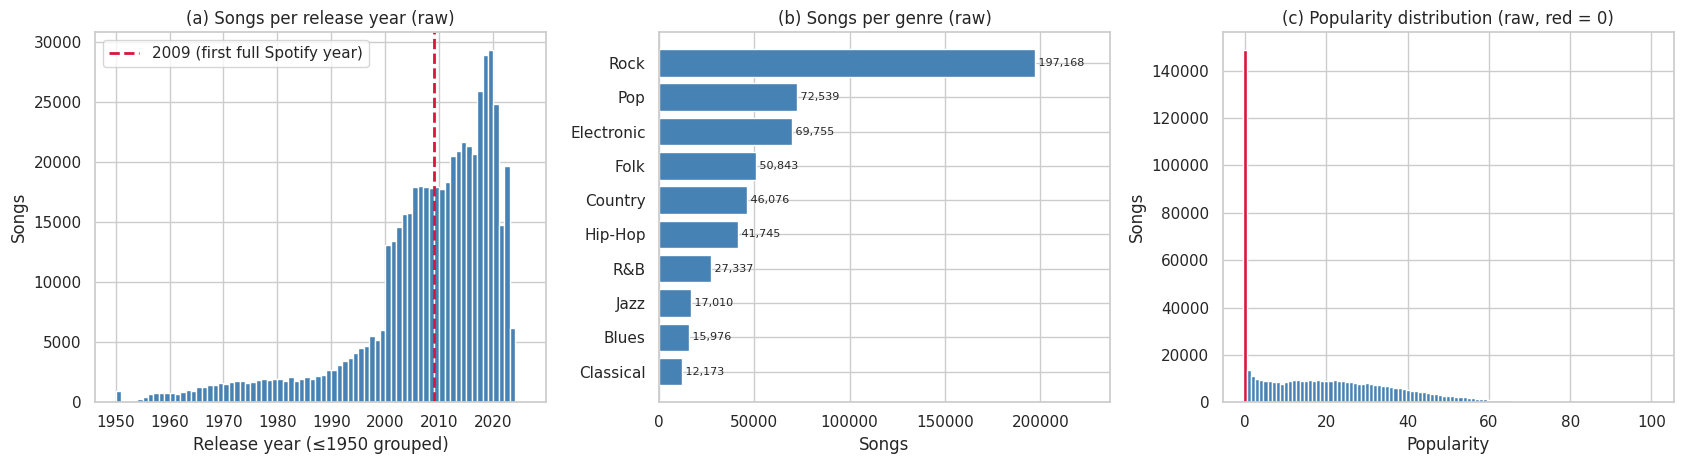

Songs released before 2009: 43.9%
popularity = 0: 27.0%
Largest / smallest genre size ratio: 16.2x


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

yr = raw["year"].clip(lower=1950)
axes[0].hist(yr, bins=np.arange(1950, 2027), color="steelblue")
axes[0].axvline(2009, color=HIGHLIGHT, ls="--", lw=2, label="2009 (first full Spotify year)")
axes[0].set(title="(a) Songs per release year (raw)", xlabel="Release year (≤1950 grouped)", ylabel="Songs")
axes[0].legend()

gc = raw["genre"].value_counts().sort_values()
axes[1].barh(gc.index, gc.values, color="steelblue")
for i, v in enumerate(gc.values):
    axes[1].text(v, i, f" {v:,}", va="center", fontsize=8)
axes[1].set(title="(b) Songs per genre (raw)", xlabel="Songs")
axes[1].set_xlim(0, gc.max() * 1.2)

pc = raw["popularity"].value_counts().reindex(range(0, 101), fill_value=0)
axes[2].bar(pc.index, pc.values, width=1.0, color=[HIGHLIGHT if i == 0 else "steelblue" for i in pc.index])
axes[2].set(title="(c) Popularity distribution (raw, red = 0)", xlabel="Popularity", ylabel="Songs")

plt.tight_layout()
save_fig("01_raw_overview")
plt.show()
print(f"Songs released before 2009: {(raw['year'] < 2009).mean():.1%}")
print(f"popularity = 0: {(raw['popularity'] == 0).mean():.1%}")
print(f"Largest / smallest genre size ratio: {gc.max() / gc.min():.1f}x")

## 1.6 Data Cleaning

**Goal**: ensure that each row represents one song with usable audio features and popularity. The flag `has_lyrics` records whether the song has valid English lyrics.

### Cleaning steps (v5)

| Step | Operation | Rationale |
|---|---|---|
| 2.1 | Type conversion | Numeric columns may be read as text |
| 2.2 | Song identity and first_year | Determine each song's original release year across **all versions** before filtering |
| 2.3 | Year filter | Focus on the streaming era |
| 2.4 | Missing and invalid values | Songs without popularity or audio features cannot be used; missing lyrics are retained |
| 2.5 | Lyrics cleaning → `lyrics_model_text` → `has_lyrics` | Fix literal `\n`, remove timestamps; fewer than 20 words → `has_lyrics = 0` |
| 2.5b | Non-English lyrics filter | The dataset contains lyrics in other languages |
| 2.6 | Exclude popularity = 0 | Mostly delisted or superseded versions |
| 2.7 | Merge multiple versions of the same song | Prevent the same song from appearing in both training and test sets |
| 2.8 | Lyrics identity and duplicate-lyrics groups | `lyrics_identity_text` → `lyrics_group_id` (SHA-256) |
| 2.9 | Cleaning log | Summary of rows removed per step |
| 2.10 | Splitting: primary (random stratified, by lyrics group) and robustness (artist groups) | train / val / test |
| 2.11 | Leakage checks | Duplicate-lyrics groups do not cross splits; artist overlap |
| 2.12 | Official MAE baseline (training-set median) | Common reference for all models |
| 2.13 | Export of two datasets | Lyrics dataset and audio dataset |
| 2.14 | Methodology sanity checks | All key checks in one table |

The order of the steps matters. For example, if a 1985 song received a remastered release in 2015, filtering each version by its own year and then deduplicating would remove the 1985 version and keep the 2015 remaster, wrongly treating an 1980s song as a streaming-era release. Computing `first_year = 1985` across all versions before filtering correctly excludes the song. For the same reason, duplicate-lyrics groups must be built **before** splitting so that each group can be assigned to a single split.

Each step is recorded in `cleaning_log`.

In [ ]:
df = raw.copy()
if CONFIG["SAMPLE_N"]:
    df = df.sample(n=min(CONFIG["SAMPLE_N"], len(df)), random_state=RANDOM_STATE)
    print(f"Debug mode: using a sample of {len(df):,} rows")

cleaning_log = []

def log_step(step, reason, data, en=""):
    prev = cleaning_log[-1]["rows_after"] if cleaning_log else len(data)
    removed = prev - len(data)
    cleaning_log.append({"step": step, "reason": reason, "label_en": en or step,
                         "rows_removed": removed, "rows_after": len(data)})
    print(f"[{step}] removed {removed:,} rows → {len(data):,} rows remaining")

log_step("0. Raw data", "Kaggle songs.csv", df, "0. Raw data")
EVIDENCE = {}

[0. Raw data] removed 0 rows → 550,622 rows remaining


### 2.1 Type Conversion

Numeric columns are converted with `pd.to_numeric(errors="coerce")`; values that cannot be converted become NaN and are handled in 2.4. All printed types should be `float64` or `int64`.

In [ ]:
numeric_cols = AUDIO_FEATURES + ["popularity", "year", "duration_ms"]
for c in numeric_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["id"] = df["id"].astype(str)
print(df[numeric_cols].dtypes)

danceability        float64
energy              float64
loudness            float64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
popularity            int64
year                  int64
duration_ms           int64
dtype: object


### 2.2 Song Identity and first_year

Each row receives a song identifier `song_key`, so that different versions of the same song share one key, and `first_year`, the earliest release year across all versions of that song. No rows are removed in this step.

A key based on the lowercase title and the full artist list treats the following as different songs:

| Version A | Version B | Issue |
|---|---|---|
| `Song` | `Song - 2011 Remaster` | Version label in the title |
| `Song` | `Song (Live at Wembley)` | Version label in the title |
| `Song` by `["A"]` | `Song (feat. B)` by `["A", "B"]` | Different title and artist list |

**Rules**
1. **Title normalization**: lowercase; remove parenthesized parts containing version keywords (remaster, live, remix, feat., edit, version, etc.); remove version descriptions after ` - `; keep only letters and digits.
2. **Main artist**: the first entry of the JSON list in `artists`.
3. `song_key = normalized title + " || " + main artist`.

Remixes and live versions differ acoustically from the original, but they are the same work with the same lyrics. Placing them in both the training and test sets would cause leakage for the lyrics models, so merging them is the safer choice; this is noted as a limitation.

The printed examples show titles before and after normalization to verify that version labels are removed while the title itself is preserved.

In [ ]:
VERSION_WORDS = (r"remaster|live|version|edit|mix|mono|stereo|acoustic|"
                 r"instrumental|feat|ft\.|with |deluxe|bonus|explicit|"
                 r"single|anniversary|re-?recorded")
PAREN_RE = re.compile(rf"\s*[\(\[][^\)\]]*(?:{VERSION_WORDS})[^\)\]]*[\)\]]")
DASH_RE = re.compile(rf"\s+-\s+.*(?:{VERSION_WORDS}).*$")

def normalize_title(title):
    raw_t = str(title).lower().strip()
    t = PAREN_RE.sub("", raw_t)
    t = DASH_RE.sub("", t)
    t = re.sub(r"[^a-z0-9 ]+", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t if t else raw_t

def main_artist(artists):
    try:
        lst = json.loads(artists)
        if isinstance(lst, list) and len(lst) > 0:
            return str(lst[0]).lower().strip()
    except (TypeError, ValueError):
        pass
    return str(artists).lower().strip()

t0 = time.time()
df["title_norm"] = df["name"].map(normalize_title)
df["main_artist"] = df["artists"].map(main_artist)
df["song_key"] = df["title_norm"] + " || " + df["main_artist"]
df["first_year"] = df.groupby("song_key")["year"].transform("min")
print(f"Song identity built ({time.time() - t0:.1f} s)")

changed = df["name"].astype(str).str.lower().str.strip() != df["title_norm"]
print(f"\nRows with a normalized title: {changed.sum():,}")
print(f"Rows: {len(df):,} → unique songs: {df['song_key'].nunique():,}")
print(f"Rows with year = 1900 (likely invalid year): {(df['year'] == 1900).sum():,}")
print("\nNormalization examples (titles with version keywords):")
examples = df.loc[changed & df["name"].astype(str).str.contains(r"[\(\-]", na=False),
                  ["name", "title_norm", "artists", "main_artist", "year", "first_year"]]
display(examples.sample(min(8, len(examples)), random_state=RANDOM_STATE))

Song identity built (5.1 s)

Rows with a normalized title: 181,455
Rows: 550,622 → unique songs: 426,109
Rows with year = 1900 (likely invalid year): 30

Normalization examples (titles with version keywords):


,name,title_norm,artists,main_artist,year,first_year
766,(Beat By) Jealousy,beat by jealousy,"[""Heart""]",heart,1983,1983
1279,(I'm) Screwed,i m screwed,"[""Titus Andronicus""]",titus andronicus,2022,2022
415796,Soon (Live),soon,"[""Tanya Tucker""]",tanya tucker,2013,2008
394137,Sgt. Pepper's Lonely Hearts Club Band - Repris...,sgt pepper s lonely hearts club band,"[""The Beatles""]",the beatles,1967,1967
91174,Collide - Alex Gaudino & Jason Rooney Remix,collide,"[""Leona Lewis"", ""Avicii"", ""Alex Gaudino"", ""Jas...",leona lewis,2011,2011
292695,Matches - Mr FijiWiji Remix,matches,"[""Ephixa"", ""Stephen Walking"", ""Aaron Richards""...",ephixa,2016,2016
362669,Quiet Nights of Quiet Stars - Live,quiet nights of quiet stars,"[""Stacey Kent""]",stacey kent,2011,2011
441007,Tarantula (feat. Butch Cassidy),tarantula,"[""Mystikal"", ""Butch Cassidy""]",mystikal,2004,2001


### Song versions

- **(a) Version keywords in song titles.** Shows that version labels are common, not rare exceptions.
- **(b) Number of versions per song** (log scale; 10 or more grouped as "10+"). Most songs have one version; songs with two or more versions (red) are the source of leakage risk.

Figure saved: figures/02_song_versions.png


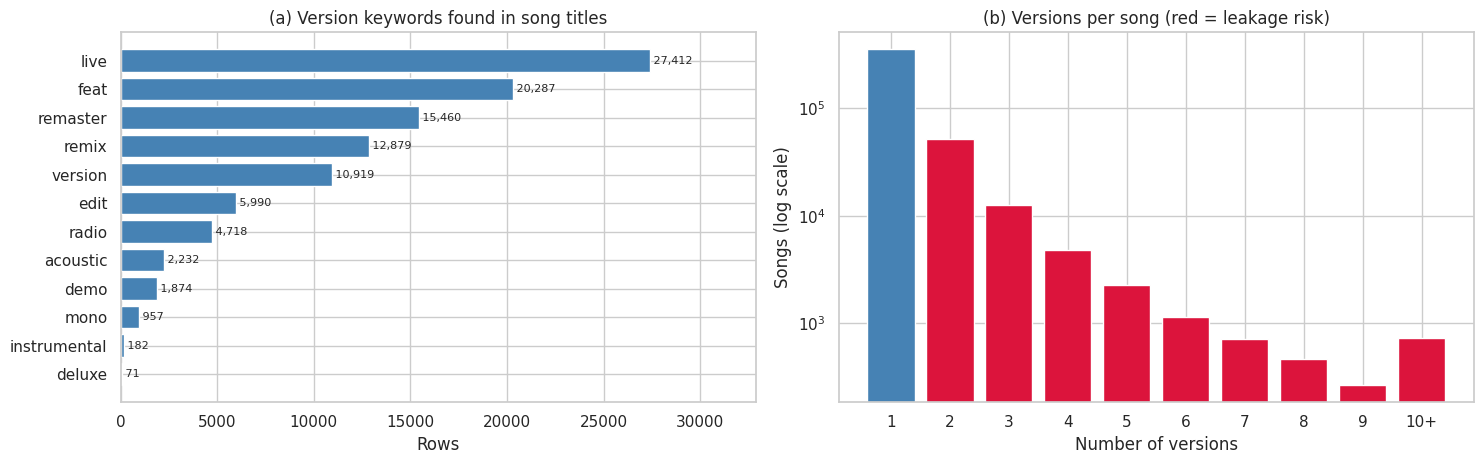

Songs with 2+ versions: 74,213 (17.4% of all songs)
These songs account for 198,726 rows


In [ ]:
kw_list = ["remaster", "live", "remix", "feat", "edit", "version", "acoustic",
           "mono", "deluxe", "radio", "demo", "instrumental"]
name_l = df["name"].astype(str).str.lower()
kw_counts = pd.Series({k: int(name_l.str.contains(k, regex=False).sum()) for k in kw_list}).sort_values()
vps = df["song_key"].value_counts()
vps_bins = vps.clip(upper=10).value_counts().sort_index()
vps_labels = [str(i) if i < 10 else "10+" for i in vps_bins.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].barh(kw_counts.index, kw_counts.values, color="steelblue")
for i, v in enumerate(kw_counts.values):
    axes[0].text(v, i, f" {v:,}", va="center", fontsize=8)
axes[0].set(title="(a) Version keywords found in song titles", xlabel="Rows")
axes[0].set_xlim(0, max(kw_counts.max(), 1) * 1.2)

colors = ["steelblue" if l == "1" else HIGHLIGHT for l in vps_labels]
axes[1].bar(vps_labels, vps_bins.values, color=colors)
axes[1].set_yscale("log")
axes[1].set(title="(b) Versions per song (red = leakage risk)", xlabel="Number of versions", ylabel="Songs (log scale)")

plt.tight_layout()
save_fig("02_song_versions")
plt.show()

multi_share = (vps > 1).mean()
EVIDENCE["songs_with_multiple_versions_pct"] = round(multi_share * 100, 1)
print(f"Songs with 2+ versions: {(vps > 1).sum():,} ({multi_share:.1%} of all songs)")
print(f"These songs account for {vps[vps > 1].sum():,} rows")

### 2.3 Year Range

Only songs **first released between 2009 and 2025** are retained.

**Rationale**
1. The study concerns popularity in the **streaming era**. Spotify launched in October 2008, so 2009 is its first full year.
2. Popularity of older songs on Spotify mainly reflects catalog listening, which is not comparable to that of streaming-era releases.
3. SQ5 compares eras within the streaming era, which requires a consistently defined year range.

**Why 2009.** The lower bound is set by an external fact (Spotify's launch), not by trying several years and selecting the one that maximizes model performance. The data are used only to assess the cost of this decision: the sensitivity table reports the number of songs retained for `YEAR_MIN` = 2000 / 2005 / 2009 / 2012 / 2015. The decision would be reconsidered only if 2009 retained too few songs (e.g., fewer than 50,000). A re-run with 2005 or 2012 is planned as a robustness check.

**Why first_year.** The population is songs released in the streaming era. A 1985 song remastered in 2015 was written and first released in 1985; using the version year would misclassify it as a 2015 release.

**Figure**
- **(a) Songs per year.** The blue line counts versions by version year (a song may be counted several times); the orange line counts each song once by `first_year`. The gap after 2009 reflects re-releases of older songs.
- **(b) Mean popularity by first_year.** Newer songs have higher mean popularity, consistent with the recency weighting of Spotify popularity (examined in SQ5).
- **(c) Share of popularity = 0 by first_year.** Year-specific peaks would indicate that zero popularity is related to release year (2.6).

Figure saved: figures/03_year_decision.png


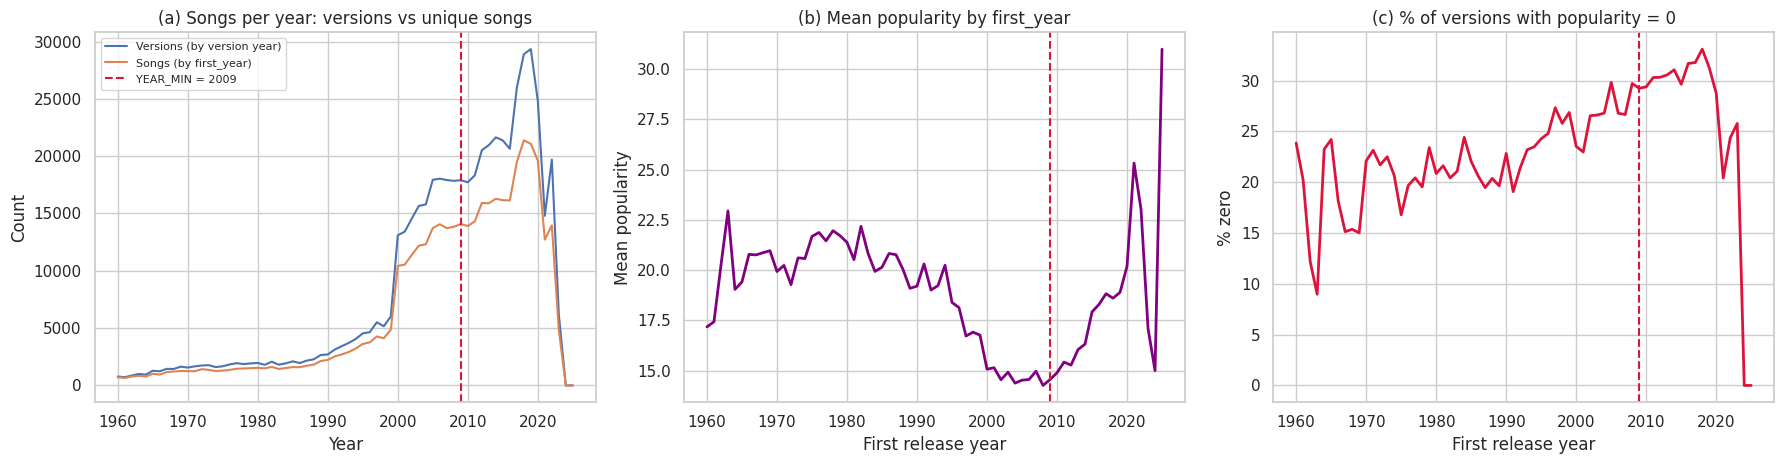

,YEAR_MIN,rows_kept,pct_of_raw,unique_songs,chosen
0,2000,415890,75.500,347980,
1,2005,345896,62.800,291113,
2,2009,279509,50.800,235758,yes
3,2012,229243,41.600,193458,
4,2015,171687,31.200,145367,


In [ ]:
plot_years = np.arange(1960, 2026)
ver_counts = df["year"].value_counts().reindex(plot_years, fill_value=0)
first_counts = df.drop_duplicates("song_key")["first_year"].value_counts().reindex(plot_years, fill_value=0)
by_year = (df.groupby("first_year")["popularity"]
             .agg(pop_mean="mean", zero_share=lambda s: (s == 0).mean())
             .reindex(plot_years))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].plot(plot_years, ver_counts.values, label="Versions (by version year)")
axes[0].plot(plot_years, first_counts.values, label="Songs (by first_year)")
axes[0].set(title="(a) Songs per year: versions vs unique songs", xlabel="Year", ylabel="Count")
axes[1].plot(plot_years, by_year["pop_mean"].values, color="purple", lw=2)
axes[1].set(title="(b) Mean popularity by first_year", xlabel="First release year", ylabel="Mean popularity")
axes[2].plot(plot_years, by_year["zero_share"].values * 100, color=HIGHLIGHT, lw=2)
axes[2].set(title="(c) % of versions with popularity = 0", xlabel="First release year", ylabel="% zero")
for ax in axes:
    ax.axvline(CONFIG["YEAR_MIN"], color=HIGHLIGHT, ls="--", lw=1.5, label=f"YEAR_MIN = {CONFIG['YEAR_MIN']}")
axes[0].legend(fontsize=8)
plt.tight_layout()
save_fig("03_year_decision")
plt.show()

rows = []
for y in [2000, 2005, 2009, 2012, 2015]:
    m = df["first_year"].between(y, CONFIG["YEAR_MAX"])
    rows.append({"YEAR_MIN": y, "rows_kept": int(m.sum()), "pct_of_raw": round(m.mean() * 100, 1),
                 "unique_songs": df.loc[m, "song_key"].nunique(),
                 "chosen": "yes" if y == CONFIG["YEAR_MIN"] else ""})
year_sensitivity = pd.DataFrame(rows)
year_sensitivity

The year filter is applied to `first_year`; the number of re-released versions whose version year lies in the range but whose original release is earlier is reported, and the step is recorded in the cleaning log.

In [ ]:
year_col = "first_year" if CONFIG["YEAR_BASIS"] == "first_year" else "year"
print(f"Year basis: {year_col}")
print(f"Raw year range: {int(df['year'].min())} – {int(df['year'].max())}")

in_range_version = df["year"].between(CONFIG["YEAR_MIN"], CONFIG["YEAR_MAX"])
in_range_first = df["first_year"].between(CONFIG["YEAR_MIN"], CONFIG["YEAR_MAX"])
n_reissue = int((in_range_version & ~in_range_first).sum())
print(f"Version year in range but song first released earlier (reissues): {n_reissue:,} rows")

df = df[df[year_col].between(CONFIG["YEAR_MIN"], CONFIG["YEAR_MAX"])]
df["year"] = df["year"].astype(int)
df["first_year"] = df["first_year"].astype(int)
log_step("1. Year filter", f"{year_col} in {CONFIG['YEAR_MIN']}–{CONFIG['YEAR_MAX']}", df, "1. Year filter")
EVIDENCE["reissue_rows"] = n_reissue
EVIDENCE["rows_after_year_filter"] = len(df)

Year basis: first_year
Raw year range: 1900 – 2025
Version year in range but song first released earlier (reissues): 29,264 rows
[1. Year filter] removed 271,113 rows → 279,509 rows remaining


### 2.4 Missing and Invalid Values

Rows are removed if popularity, year, or any audio feature is missing, if popularity lies outside 0–100, or if an audio feature lies outside its valid range.

Missing lyrics are **not** a reason for removal. Songs without lyrics are retained in the audio dataset (`has_lyrics = 0`) and excluded only from the lyrics dataset; the validity of lyrics is assessed in 2.5.

**Deletion versus imputation**

| Option | Advantages | Disadvantages | Decision |
|---|---|---|---|
| **Deletion** | No fabricated values; transparent | Smaller sample | Used when the share removed is small |
| Mean / median imputation | Sample size preserved | Reduces variance; distorts correlations | Not used |
| Model-based imputation (KNN, MICE) | More accurate | Complex; risk of leakage | Not used |

Rows are deleted when the share affected is below 5%. Missing popularity leaves no target; missing audio features would prevent the audio and lyrics models from being compared on the same songs.

**Outliers versus errors.** Extreme but plausible values (e.g., tempo = 210) are retained. Physically impossible values or algorithm failures (e.g., tempo = 0, or a value of 1.5 for a feature bounded in [0, 1]) are removed. Only the valid ranges documented by Spotify (`AUDIO_RANGES`) are used, not statistical rules such as three standard deviations.

**Figure**: distributions of the nine audio features (plotted from a sample of 100,000 songs; counts in titles refer to the full data). Dashed lines mark the valid range; a red title indicates invalid values.

Figure saved: figures/04_audio_ranges.png


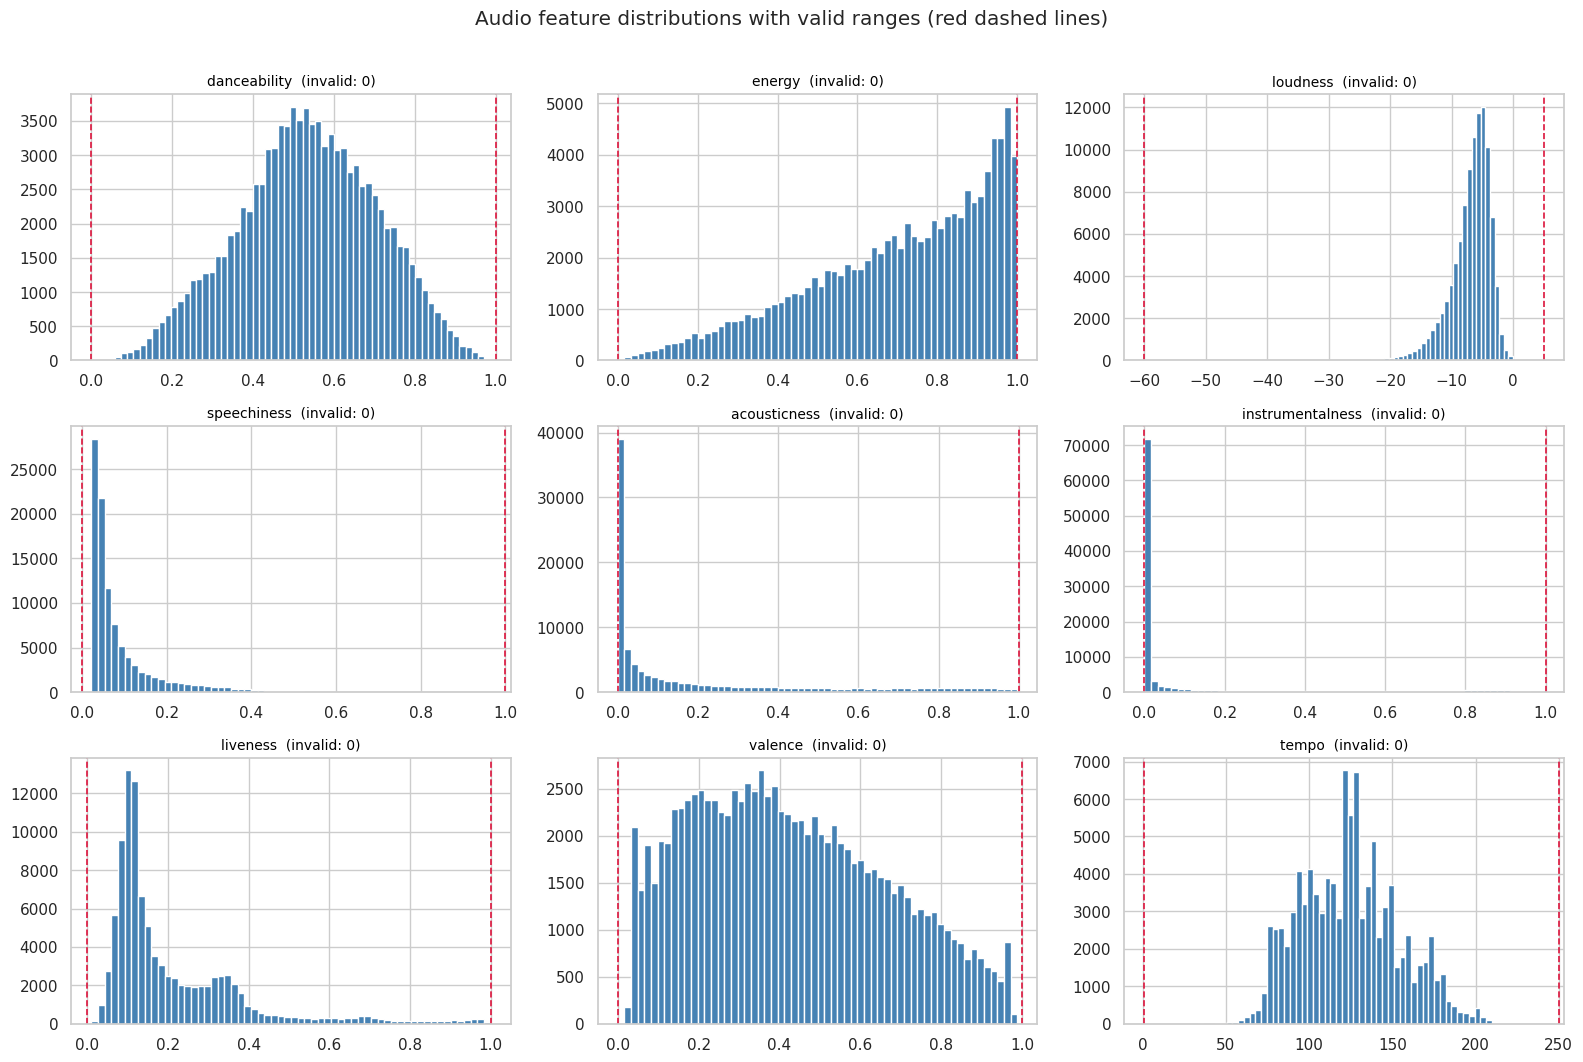

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(16, 10.5))
plot_sample = df.sample(min(100_000, len(df)), random_state=RANDOM_STATE)
for ax, c in zip(axes.ravel(), AUDIO_FEATURES):
    lo, hi = AUDIO_RANGES[c]
    n_bad = int((~df[c].between(lo, hi)).sum())
    ax.hist(plot_sample[c].dropna(), bins=60, color="steelblue")
    ax.axvline(lo, color=HIGHLIGHT, ls="--", lw=1.2)
    ax.axvline(hi, color=HIGHLIGHT, ls="--", lw=1.2)
    ax.set_title(f"{c}  (invalid: {n_bad:,})", color=HIGHLIGHT if n_bad else "black", fontsize=10)
fig.suptitle("Audio feature distributions with valid ranges (red dashed lines)", y=1.01)
plt.tight_layout()
save_fig("04_audio_ranges")
plt.show()

Rows with missing key fields are removed first (missing lyrics are replaced by an empty string and retained), then rows with popularity outside 0–100, and finally rows with any audio feature outside its valid range; the table lists the number of invalid values per feature.

In [ ]:
key_cols = ["popularity", "year"] + AUDIO_FEATURES
miss = df[key_cols].isna().sum()
print("Missing values in key columns:")
print(miss[miss > 0] if (miss > 0).any() else "   (none)")
print(f"(Reference) missing lyrics: {df['lyrics'].isna().sum():,} rows → not dropped; flagged as has_lyrics = 0 in 2.5")
df["lyrics"] = df["lyrics"].fillna("")

df = df.dropna(subset=key_cols)
log_step("2. Missing key fields", "missing popularity / year / any of the 9 audio features (missing lyrics are kept)", df, "2. Missing key fields")

df = df[df["popularity"].between(0, 100)]
log_step("3. Invalid popularity", "popularity outside 0–100", df, "3. Invalid popularity")

bad_mask = pd.Series(False, index=df.index)
range_rows = []
for c, (lo, hi) in AUDIO_RANGES.items():
    m = ~df[c].between(lo, hi)
    range_rows.append({"feature": c, "valid_range": f"[{lo}, {hi}]", "n_invalid": int(m.sum())})
    bad_mask |= m
display(pd.DataFrame(range_rows))

df = df[~bad_mask]
log_step("4. Invalid audio values", "e.g., tempo = 0 (beat detection failed)", df, "4. Invalid audio values")
EVIDENCE["invalid_audio_rows"] = int(bad_mask.sum())

Missing values in key columns:
   (none)
(Reference) missing lyrics: 0 rows → not dropped; flagged as has_lyrics = 0 in 2.5
[2. Missing key fields] removed 0 rows → 279,509 rows remaining
[3. Invalid popularity] removed 0 rows → 279,509 rows remaining


,feature,valid_range,n_invalid
0,danceability,"[0.0, 1.0]",0
1,energy,"[0.0, 1.0]",0
2,speechiness,"[0.0, 1.0]",0
3,acousticness,"[0.0, 1.0]",0
4,instrumentalness,"[0.0, 1.0]",0
5,liveness,"[0.0, 1.0]",0
6,valence,"[0.0, 1.0]",0
7,loudness,"[-60.0, 5.0]",0
8,tempo,"[1.0, 250.0]",0


[4. Invalid audio values] removed 0 rows → 279,509 rows remaining


### 2.5 Lyrics Cleaning → `lyrics_model_text`

This step removes non-lyrical content and creates **`lyrics_model_text`**, which is used for all lyrics features and TF-IDF in Notebook 2.

**Two lyrics representations**

| Column | Purpose | Cleaning | Created in |
|---|---|---|---|
| **`lyrics_model_text`** | Modeling (lyrics features, TF-IDF) | Light: case, punctuation, and line breaks are preserved because they inform features such as repeated lines and sentiment | 2.5 |
| **`lyrics_identity_text`** | Duplicate detection only | Aggressive: lowercase, punctuation removed, apostrophes unified, whitespace and line breaks collapsed | 2.8 |

Modeling requires preserving information, whereas duplicate detection requires ignoring irrelevant formatting differences; a single representation cannot serve both purposes.

**Literal `\n` in the raw lyrics.** If line breaks are stored as the two characters backslash + n rather than as real newlines, `text.split("\n")` finds no line breaks, every song has a single line, and line-based repetition features fail. Tokenization is also affected: `kids\nAnd` becomes `kids` and `nand` after lowercasing. The next cell first confirms this issue in the data (using `repr()`, which displays the stored characters) and then corrects it.

**Cleaning rules**
1. Convert literal `\n` and `\r` to real line breaks; convert `\'` and `\"` to quotes.
2. Remove LRC timestamps (e.g., `[01:23.45]`).
3. Remove section tags (e.g., `[Chorus]`, `[Verse 1]`).
4. Remove redundant whitespace and empty lines.

Lyrics with a literal \n: 0.0%
Lyrics with real line breaks: 99.9%

repr() of the first song (what is actually stored):
"He said he came from Jamaica,\\nhe owned a couple acres A couple fake visas 'cause he never got his\\npapers Gave up on love fucking with them heart bre"
Figure saved: figures/05_newline_diagnosis.png


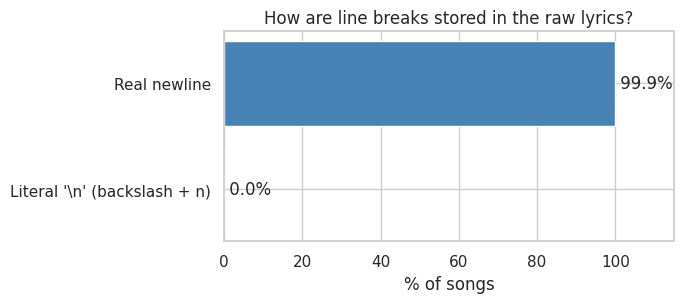

In [ ]:
s = df["lyrics"].astype(str)
has_literal_nl = s.str.contains("\\n", regex=False)
has_real_nl = s.str.contains("\n", regex=False)
print(f"Lyrics with a literal \\n: {has_literal_nl.mean():.1%}")
print(f"Lyrics with real line breaks: {has_real_nl.mean():.1%}")
print("\nrepr() of the first song (what is actually stored):")
print(repr(s.iloc[0][:150]))
EVIDENCE["literal_newline_pct"] = round(has_literal_nl.mean() * 100, 1)

fig, ax = plt.subplots(figsize=(7, 3.2))
vals = [has_literal_nl.mean() * 100, has_real_nl.mean() * 100]
ax.barh(["Literal '\\n' (backslash + n)", "Real newline"], vals, color=[HIGHLIGHT, "steelblue"])
for i, v in enumerate(vals):
    ax.text(v, i, f" {v:.1f}%", va="center")
ax.set(xlim=(0, 115), xlabel="% of songs", title="How are line breaks stored in the raw lyrics?")
plt.tight_layout()
save_fig("05_newline_diagnosis")
plt.show()

`clean_lyrics()` applies the cleaning rules to every song and creates `lyrics_model_text`, together with the number of English words (`lyrics_n_words`) and lines (`lyrics_n_lines`). The printed example compares the stored text before and after cleaning.

In [ ]:
TS_RE = re.compile(r"\[\d{1,2}:\d{2}(?:[.:]\d{1,3})?\]")
TAG_RE = re.compile(r"\[[^\]]{0,40}\]")
SPACE_RE = re.compile(r"[ \t]+")
WORD_RE = r"[a-z']+"

def clean_lyrics(text):
    text = str(text)
    text = text.replace("\\r\\n", "\n").replace("\\n", "\n").replace("\\r", "\n")
    text = text.replace("\\'", "'").replace('\\"', '"')
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = TS_RE.sub(" ", text)
    text = TAG_RE.sub(" ", text)
    lines = [SPACE_RE.sub(" ", ln).strip() for ln in text.split("\n")]
    return "\n".join(ln for ln in lines if ln)

t0 = time.time()
df["lyrics_model_text"] = df["lyrics"].map(clean_lyrics)
df["lyrics_n_words"] = df["lyrics_model_text"].str.lower().str.count(WORD_RE)
df["lyrics_n_lines"] = df["lyrics_model_text"].str.count("\n") + 1
print(f"Lyrics cleaned ({time.time() - t0:.1f} s)")

ex = df.iloc[0]
print("\n--- Before cleaning (repr, first 150 chars) ---\n", repr(str(ex["lyrics"])[:150]))
print("\n--- After cleaning (printed; should show real line breaks) ---\n", ex["lyrics_model_text"][:250])
print(f"\nMedian lines per song: {df['lyrics_n_lines'].median():.0f} (if this is 1, line breaks were not fixed)")

Lyrics cleaned (67.5 s)

--- Before cleaning (repr, first 150 chars) ---
 "He said he came from Jamaica,\\nhe owned a couple acres A couple fake visas 'cause he never got his\\npapers Gave up on love fucking with them heart bre"

--- After cleaning (printed; should show real line breaks) ---
 He said he came from Jamaica,
he owned a couple acres A couple fake visas 'cause he never got his
papers Gave up on love fucking with them heart breakers But he was
getting money with the movers and the shakers He was mixed with a
couple things, bald

Median lines per song: 37 (if this is 1, line breaks were not fixed)


### Word-count threshold `MIN_WORDS` → `has_lyrics`

This step determines the number of words below which a song is considered to have no valid lyrics. Songs below the threshold are flagged `has_lyrics = 0` rather than removed:
- The **lyrics dataset** uses only songs with `has_lyrics = 1`.
- The **audio dataset** keeps both `has_lyrics = 0` and `has_lyrics = 1`.
- The **main comparison** (audio-only vs audio + lyrics) uses only songs with `has_lyrics = 1`, so that both models are evaluated on the same songs.

"No valid lyrics" includes empty lyrics, lyrics reading only "Instrumental", one or two lines only, and incompletely retrieved lyrics.

**Decision rule (three pieces of evidence)**
1. **Share curve** (panel b): the share of songs flagged as having no lyrics as a function of the threshold. The threshold is placed before the curve becomes steep, so that the flag captures the tail of the distribution rather than ordinary short songs.
2. **Samples by word-count range** (cell after next): five songs each with 1–9, 10–19, and 20–29 words. If most 10–19-word samples are not complete lyrics while 20–29-word samples are, the threshold is set at 20.
3. **Upper limit**: the share of songs with some words that are flagged by the threshold should be below 2%, to avoid altering the composition of the lyrics dataset.

The shares in panel (b) and in the sensitivity table include songs with no lyrics at all (0 words), which are flagged regardless of the threshold, so the curve does not necessarily start at 0%.

**Figure**
- **(a)** Distribution of lyrics length (0–400 words); the dashed line is the threshold.
- **(b)** Share curve; the dot marks the chosen threshold and the dotted line the 2% reference.
- **(c)** Lines per song, verifying that the line-break correction worked (a dispersed distribution with a median of roughly 30–60 lines is expected).

Lyrics word count summary (after cleaning):
count   279,509.000
mean        261.100
std         160.600
min           0.000
1%           38.000
5%           76.000
25%         156.000
50%         229.000
75%         323.000
95%         567.000
99%         802.000
max       5,341.000
Name: lyrics_n_words, dtype: float64
Figure saved: figures/06_lyrics_threshold.png


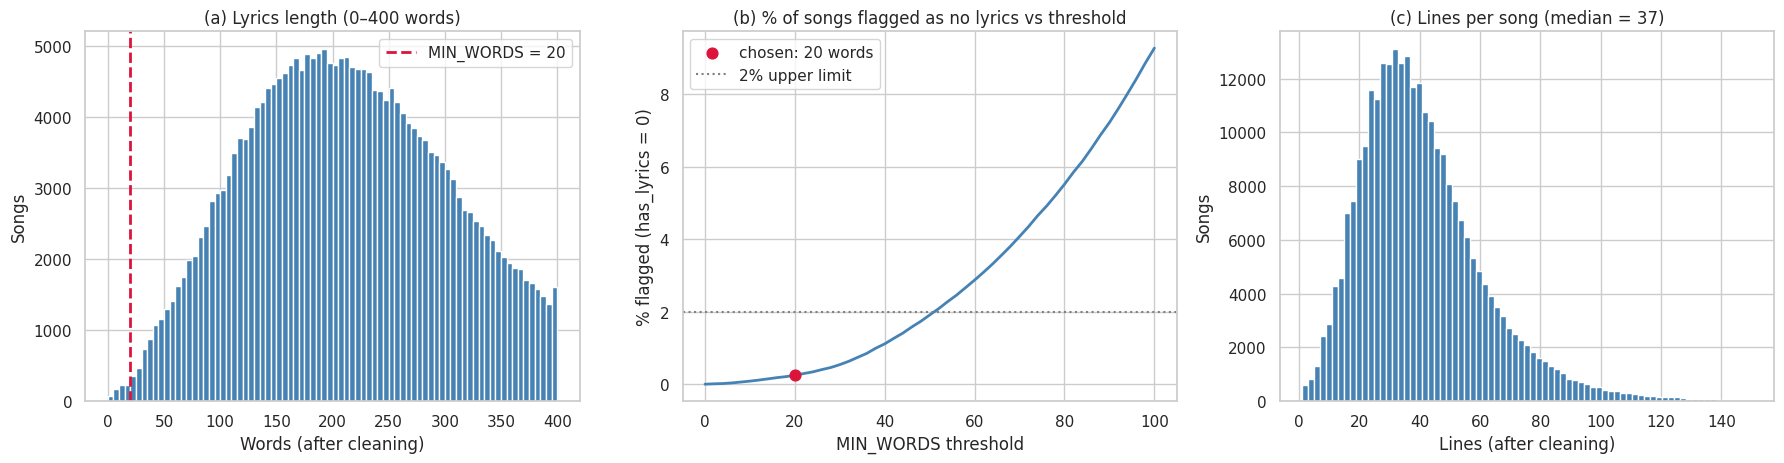

,MIN_WORDS,songs_flagged_no_lyrics,pct_flagged_no_lyrics,chosen
0,5,74,0.030,
1,10,236,0.080,
2,20,685,0.250,yes
3,30,1509,0.540,
4,50,5341,1.910,


In [ ]:
wc = df["lyrics_n_words"]
print("Lyrics word count summary (after cleaning):")
print(wc.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1))

thresholds = np.arange(0, 101, 2)
pct_removed = np.array([(wc < t).mean() * 100 for t in thresholds])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].hist(wc[wc <= 400], bins=80, color="steelblue")
axes[0].axvline(CONFIG["MIN_WORDS"], color=HIGHLIGHT, ls="--", lw=2, label=f"MIN_WORDS = {CONFIG['MIN_WORDS']}")
axes[0].set(title="(a) Lyrics length (0–400 words)", xlabel="Words (after cleaning)", ylabel="Songs")
axes[0].legend()

axes[1].plot(thresholds, pct_removed, color="steelblue", lw=2)
axes[1].scatter([CONFIG["MIN_WORDS"]], [(wc < CONFIG["MIN_WORDS"]).mean() * 100], color=HIGHLIGHT, s=60, zorder=5,
                label=f"chosen: {CONFIG['MIN_WORDS']} words")
axes[1].axhline(2, color="gray", ls=":", label="2% upper limit")
axes[1].set(title="(b) % of songs flagged as no lyrics vs threshold", xlabel="MIN_WORDS threshold", ylabel="% flagged (has_lyrics = 0)")
axes[1].legend()

ln = df["lyrics_n_lines"]
axes[2].hist(ln[ln <= 150], bins=75, color="steelblue")
axes[2].set(title=f"(c) Lines per song (median = {ln.median():.0f})", xlabel="Lines (after cleaning)", ylabel="Songs")

plt.tight_layout()
save_fig("06_lyrics_threshold")
plt.show()

cands = [5, 10, 20, 30, 50]
words_sensitivity = pd.DataFrame({
    "MIN_WORDS": cands,
    "songs_flagged_no_lyrics": [int((wc < t).sum()) for t in cands],
    "pct_flagged_no_lyrics": [round((wc < t).mean() * 100, 2) for t in cands],
})
words_sensitivity["chosen"] = np.where(words_sensitivity["MIN_WORDS"] == CONFIG["MIN_WORDS"], "yes", "")
words_sensitivity

Five randomly selected lyrics are printed for each word-count range (1–9, 10–19, 20–29 words) to inspect whether short texts are complete lyrics.

In [ ]:
for lo, hi in [(1, 9), (10, 19), (20, 29)]:
    bucket = df.loc[wc.between(lo, hi), "lyrics_model_text"]
    print(f"\n========== {lo}–{hi} words ({len(bucket):,} songs) ==========")
    for t in bucket.sample(min(5, len(bucket)), random_state=RANDOM_STATE):
        print("  •", t.replace("\n", " / ")[:160])


========== 1–9 words (216 songs) ==========
  • Wave of Death
  • your body
  • Bring That Old School Sound To The New Shit
  • Let's play the game / Let's play the game
  • We're the fuckin' animals! / ♪ / ♪ / We're the fuckin' animals!

========== 10–19 words (449 songs) ==========
  • Think positive / Be positive / Positive / Positive / Think positive / Be positive / Positive / Positive
  • I remember how you walked away / And how you did me wrong / I remember how you walked away
  • It's time to go back down the rabbit hole / This was your year, 2017
  • I'm up in the woods / I'm down on my mind / I'm building a still / To slow down the time
  • Close / We're living close / Close to the edge / Close / Close to the edge / Close to the edge

========== 20–29 words (824 songs) ==========
  • Turkey! / Montecristo! / Grilled cheese! / Meatball! / Liverwurst! / Shrimp Po'boy! / Fluffernutter! / Shawarma! / Reuben! / Cuban! / BLT! / Eggplant parm! / Ch
  • Follow me, follow me / Free me

`has_lyrics` is set to 1 for songs with at least `MIN_WORDS` English words. `has_text` additionally flags songs with enough lyric text in any script (≥ 20 tokens or ≥ 40 non-ASCII letters), which defines the songs checked by the language filter in 2.5b.

In [ ]:
df["has_lyrics"] = (df["lyrics_n_words"] >= CONFIG["MIN_WORDS"]).astype(int)
EVIDENCE["no_lyrics_pct"] = round((df["has_lyrics"] == 0).mean() * 100, 2)
EVIDENCE["min_words_removed_pct"] = round(((wc > 0) & (wc < CONFIG["MIN_WORDS"])).mean() * 100, 2)
print(f"has_lyrics = 1 (valid lyrics): {(df['has_lyrics'] == 1).sum():,} songs ({(df['has_lyrics'] == 1).mean():.1%})")
print(f"has_lyrics = 0 (no valid lyrics): {(df['has_lyrics'] == 0).sum():,} songs, of which {(wc == 0).sum():,} have no words at all")
print("Songs with has_lyrics = 0 are excluded from the lyrics dataset but kept in the audio dataset")

LETTER_RE = re.compile(r"[^\W\d_]+")
df["lyrics_n_tokens_any"] = df["lyrics_model_text"].str.count(LETTER_RE)
df["lyrics_n_nonascii_letters"] = df["lyrics_model_text"].map(lambda t: sum(1 for ch in t if ch.isalpha() and ord(ch) > 127))
df["has_text"] = ((df["lyrics_n_tokens_any"] >= CONFIG["MIN_WORDS"]) | (df["lyrics_n_nonascii_letters"] >= 2 * CONFIG["MIN_WORDS"])).astype(int)
hidden = (df["has_text"] == 1) & (df["has_lyrics"] == 0)
print(f"Songs with enough lyric text but < {CONFIG['MIN_WORDS']} English words: {hidden.sum():,} → mostly Chinese, Korean, Japanese, etc.; 2.5b will detect and exclude them")

has_lyrics = 1 (valid lyrics): 278,824 songs (99.8%)
has_lyrics = 0 (no valid lyrics): 685 songs, of which 20 have no words at all
Songs with has_lyrics = 0 are excluded from the lyrics dataset but kept in the audio dataset
Songs with enough lyric text but < 20 English words: 55 → mostly Chinese, Korean, Japanese, etc.; 2.5b will detect and exclude them


### 2.5b English-Lyrics Filter

This step identifies songs whose lyrics are not in English and excludes them.

Although the dataset is labeled as English songs, lyrics were matched from LRCLIB by title and artist, and some are in other languages (e.g., Spanish, Korean). This causes two problems:
1. The study population is English-language songs.
2. The TF-IDF stop words and the sentiment lexicon (VADER) used in Notebook 2 are English; features computed on non-English lyrics would be distorted (e.g., sentiment scores of 0, incorrect word counts).

**Metrics**

| Metric | Definition | Typical value, English | Typical value, non-English |
|---|---|---|---|
| **`en_stopword_ratio`** | Share of tokens that are English stop words (the, and, you, is, to, …; sklearn list) | approx. 0.4–0.6 | Spanish, French, German: approx. 0.05–0.15 |
| **`non_ascii_ratio`** | Share of letters outside a–z (e.g., é, ñ, 한, 日) | close to 0 | Korean, Japanese, Chinese: close to 1; accented languages: approx. 0.02–0.10 |

**Rule**: `en_stopword_ratio ≥ 0.25` **and** `non_ascii_ratio ≤ 0.10` → English lyrics.

**Songs checked: `has_text = 1`.** The word count in 2.5 counts only tokens made of English letters (`[a-z']+`), so Chinese, Korean, and Japanese lyrics have zero words under that definition. Checking only songs with `has_lyrics = 1` would therefore misclassify these songs as having no lyrics and leave them in the audio dataset. The language check is applied to songs with **at least 20 words in any language or at least 40 non-ASCII letters** (`has_text = 1`). Songs reading only "Instrumental" or containing one or two words are not checked and remain `has_lyrics = 0`.

Stop words are the most frequent and stable words of a language; English lyrics contain many of them, while lyrics in other languages have a low stop-word ratio even when they include some English words. Stop-word frequency is a standard simple method for language identification.

**Choice of threshold**
1. **Data-driven (panel a)**: the stop-word ratio is typically bimodal (English and non-English). The threshold is placed in the valley between the two modes to minimize misclassification.
2. **Sensitivity table**: the number of songs excluded for thresholds 0.15 / 0.20 / 0.25 / 0.30 / 0.35. Similar counts between 0.20 and 0.30 indicate that the result is insensitive to the threshold.
3. **External validation**: 3,000 randomly sampled songs with lyrics are classified with `langdetect`. The rule is adopted only if agreement is at least 95%; disagreements are printed for inspection.
4. **Samples**: lyrics classified as non-English and lyrics near the threshold are printed for inspection.

The rule rather than `langdetect` is applied to the full data because it is fast, deterministic, and interpretable; `langdetect` is slower, non-deterministic, and opaque, and is therefore used only for validation on a sample.

**Limitations**
- Mixed-language songs (e.g., Spanish verses with an English chorus) may have an intermediate stop-word ratio and be excluded.
- The language of songs without lyric text cannot be determined; these songs remain in the audio dataset, which may contain a small number of non-English songs.

**Figure**
- **(a)** Distribution of the English stop-word ratio with the threshold.
- **(b)** Distribution of the non-ASCII letter ratio (log y-axis) with the threshold; the rightmost bars are mostly Korean, Japanese, and similar scripts.
- **(c)** Joint density of the two metrics; songs inside the box are classified as English.

Language metrics computed (61.3 s)
Songs with lyric text flagged as non-English: 7,060 (2.53%)
Figure saved: figures/06b_language_filter.png


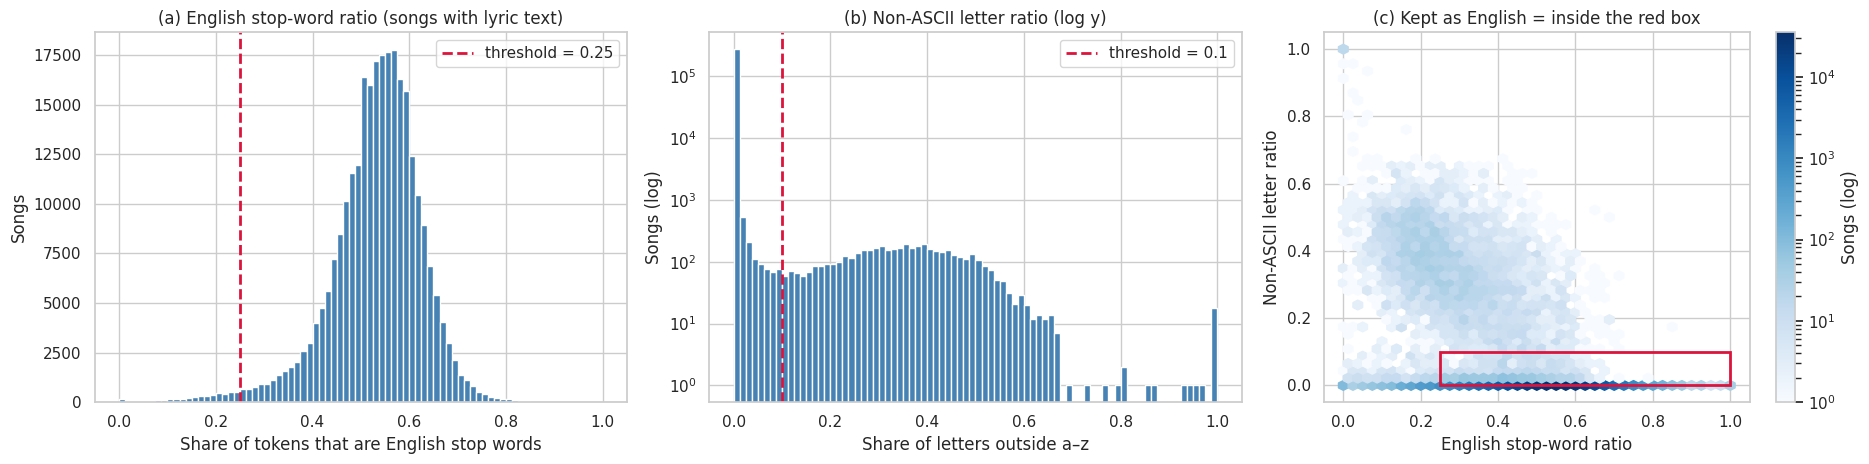

,EN_STOPWORD_THRESHOLD,songs_flagged_non_english,pct_of_songs_with_lyrics,chosen
0,0.150,5307,1.900,
1,0.200,5914,2.120,
2,0.250,7060,2.530,yes
3,0.300,9339,3.350,
4,0.350,13791,4.950,



===== Examples flagged as non-English (5 random songs, first 120 chars) =====
  • 反反覆覆 共你既遠且近 / 始終我都是想抱緊 / 身邊知己 亦說你我很相襯 / 等有日會預言成真 / 24 hours 未停想念 / 分秒都想與你遇見 / 來電時彷彿坐於針氈 / 有事發生 在這天 / You kiss me so swee
  • 이상한 꼬마 숨 쉬듯 노래했네 / 어디든 좋아 음악이 하고 싶었네 / 오직 노래 심장을 뛰게 하던 thing / 하나뿐이던 길을 걸었지만 / 쉽지 않아 실패와 절망 / 지친 날 누군가 불러 세워 건넨 말 / You'
  • Time goes ticking again / Time goes ticking again / Time goes ticking aga- / Tickin' over / Time goes, Time goes tickin'
  • 너를 처음 본 이후 모든 사소한 이유는 필요 없어진 feeling / 초의 백분위까지 느껴지는 magic 섬세한 one minute / 내 모든 신경이 전부 곤두서 너를 알기를 원해 / 낯설고 미묘한 작은 떨림마저 
  • Yeah, yeah 모든 건 느껴진 그대로 / 나만의 색은 마치 pink, blue, black, white / 그 누구보다 좀 더 특별해 / 세상 단 하나뿐인 color, oh alright / 숨겨봐도 숨겨지지 

===== Examples near the threshold (stop-word ratio 0.20–0.30) =====
  • (0.23) Yhhhh Yhhhh Yhhhh / It's IYCE prince JNR / Baby, baby, see how ma heart dey beat, Bakam / Wetin na won do, omo na emerge
  • (0.30) Ready, ready go! / Keep it going on! / Never, never stop! / Keep it going on! / Don'

In [ ]:
EN_STOP = set(ENGLISH_STOP_WORDS)
def language_stats(text):
    toks = LETTER_RE.findall(text.lower())
    n = len(toks)
    letters = "".join(toks)
    n_letters = len(letters)
    non_ascii = sum(1 for ch in letters if ord(ch) > 127)
    en = sum(1 for t in toks if t in EN_STOP)
    return (en / n if n else 0.0, non_ascii / n_letters if n_letters else 0.0)

TH_STOP = CONFIG["LANG_MIN_EN_STOPWORD_RATIO"]
TH_ASCII = CONFIG["LANG_MAX_NON_ASCII_RATIO"]
lyr_mask = df["has_text"] == 1
t0 = time.time()
stats = np.array([language_stats(t) for t in df.loc[lyr_mask, "lyrics_model_text"].values])
df["en_stopword_ratio"] = np.nan
df["non_ascii_ratio"] = np.nan
df.loc[lyr_mask, "en_stopword_ratio"] = stats[:, 0]
df.loc[lyr_mask, "non_ascii_ratio"] = stats[:, 1]
rule_en = (df["en_stopword_ratio"] >= TH_STOP) & (df["non_ascii_ratio"] <= TH_ASCII)
non_english = lyr_mask & ~rule_en
print(f"Language metrics computed ({time.time() - t0:.1f} s)")
print(f"Songs with lyric text flagged as non-English: {non_english.sum():,} ({non_english.sum() / lyr_mask.sum():.2%})")

ly = df.loc[lyr_mask]
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
axes[0].hist(ly["en_stopword_ratio"], bins=80, color="steelblue")
axes[0].axvline(TH_STOP, color=HIGHLIGHT, ls="--", lw=2, label=f"threshold = {TH_STOP}")
axes[0].set(title="(a) English stop-word ratio (songs with lyric text)", xlabel="Share of tokens that are English stop words", ylabel="Songs")
axes[0].legend()
axes[1].hist(ly["non_ascii_ratio"], bins=80, color="steelblue")
axes[1].set_yscale("log")
axes[1].axvline(TH_ASCII, color=HIGHLIGHT, ls="--", lw=2, label=f"threshold = {TH_ASCII}")
axes[1].set(title="(b) Non-ASCII letter ratio (log y)", xlabel="Share of letters outside a–z", ylabel="Songs (log)")
axes[1].legend()
hb = axes[2].hexbin(ly["en_stopword_ratio"], ly["non_ascii_ratio"], gridsize=40, bins="log", cmap="Blues", mincnt=1)
axes[2].add_patch(plt.Rectangle((TH_STOP, 0), 1 - TH_STOP, TH_ASCII, fill=False, ec=HIGHLIGHT, lw=2))
axes[2].set(title="(c) Kept as English = inside the red box", xlabel="English stop-word ratio", ylabel="Non-ASCII letter ratio")
fig.colorbar(hb, ax=axes[2], label="Songs (log)")
plt.tight_layout()
save_fig("06b_language_filter")
plt.show()

lang_sensitivity = pd.DataFrame({
    "EN_STOPWORD_THRESHOLD": [0.15, 0.20, 0.25, 0.30, 0.35],
    "songs_flagged_non_english": [int((lyr_mask & ~((df["en_stopword_ratio"] >= t) & (df["non_ascii_ratio"] <= TH_ASCII))).sum()) for t in [0.15, 0.20, 0.25, 0.30, 0.35]],
})
lang_sensitivity["pct_of_songs_with_lyrics"] = (lang_sensitivity["songs_flagged_non_english"] / lyr_mask.sum() * 100).round(2)
lang_sensitivity["chosen"] = np.where(lang_sensitivity["EN_STOPWORD_THRESHOLD"] == TH_STOP, "yes", "")
display(lang_sensitivity)

print("\n===== Examples flagged as non-English (5 random songs, first 120 chars) =====")
for t in df.loc[non_english, "lyrics_model_text"].sample(min(5, int(non_english.sum())), random_state=RANDOM_STATE):
    print("  •", t.replace("\n", " / ")[:120])
near = lyr_mask & df["en_stopword_ratio"].between(TH_STOP - 0.05, TH_STOP + 0.05)
print(f"\n===== Examples near the threshold (stop-word ratio {TH_STOP - 0.05:.2f}–{TH_STOP + 0.05:.2f}) =====")
for t, r in df.loc[near, ["lyrics_model_text", "en_stopword_ratio"]].sample(min(5, int(near.sum())), random_state=RANDOM_STATE).values:
    print(f"  • ({r:.2f})", t.replace("\n", " / ")[:120])

**External validation.** A random sample of `LANG_VALIDATION_SAMPLE` songs with lyric text is classified with `langdetect`. The agreement rate with the rule, the cross-tabulation, the most frequent detected languages, and examples of disagreement are reported. If `langdetect` is not installed, the validation is skipped.

In [ ]:
# ===== External validation: compare with langdetect on a random sample (skipped if not installed) =====
try:
    from langdetect import detect, DetectorFactory
    DetectorFactory.seed = 0
    lang_available = True
except ImportError:
    lang_available = False

def safe_detect(text):
    try:
        return detect(text[:1000])
    except Exception:
        return "unknown"

if lang_available:
    samp = df.loc[lyr_mask].sample(min(CONFIG["LANG_VALIDATION_SAMPLE"], int(lyr_mask.sum())), random_state=RANDOM_STATE).copy()
    t0 = time.time()
    samp["langdetect"] = samp["lyrics_model_text"].map(safe_detect)
    samp["rule_english"] = (samp["en_stopword_ratio"] >= TH_STOP) & (samp["non_ascii_ratio"] <= TH_ASCII)
    samp["ld_english"] = samp["langdetect"] == "en"
    agree = (samp["rule_english"] == samp["ld_english"]).mean()
    EVIDENCE["lang_rule_agreement_pct"] = round(agree * 100, 1)
    print(f"langdetect sample of {len(samp):,} songs ({time.time() - t0:.1f} s): rule vs langdetect agreement = {agree:.1%} (target ≥ 95%)")
    display(pd.crosstab(samp["rule_english"].map({True: "rule: English", False: "rule: non-English"}),
                        samp["ld_english"].map({True: "langdetect: en", False: "langdetect: other"})))
    print("Languages detected by langdetect (top 8):", samp["langdetect"].value_counts().head(8).to_dict())
    disagree = samp[samp["rule_english"] != samp["ld_english"]]
    print("\n===== Disagreement examples (up to 5) =====")
    for _, r in disagree.head(5).iterrows():
        print(f"  • rule={'EN' if r['rule_english'] else 'non-EN'} / langdetect={r['langdetect']} / stop={r['en_stopword_ratio']:.2f}:", r["lyrics_model_text"].replace("\n", " / ")[:100])
else:
    EVIDENCE["lang_rule_agreement_pct"] = None
    print("langdetect is not installed; skipping external validation (run the install cell in 1.1 on Colab)")

langdetect sample of 3,000 songs (18.0 s): rule vs langdetect agreement = 98.0% (target ≥ 95%)


ld_english,langdetect: en,langdetect: other
rule_english,,
rule: English,2933,7
rule: non-English,52,8


Languages detected by langdetect (top 8): {'en': 2985, 'es': 3, 'ko': 3, 'ja': 2, 'id': 2, 'de': 2, 'cy': 1, 'af': 1}

===== Disagreement examples (up to 5) =====
  • rule=non-EN / langdetect=en / stop=0.11: Let the bass cannon kick it / Let the bass cannon kick it / Let the bass cannon kick it / Let the ba
  • rule=non-EN / langdetect=en / stop=0.08: Rubbed raw / Curdled blood ejaculation / Stained to the marrow / Repetitive negation / Urethetic cha
  • rule=non-EN / langdetect=en / stop=0.16: If you gonna bust / ♪ / Don't panic / If you gonna bust / Don't panic / ♪ / Cause I gotta wooh wooh 
  • rule=non-EN / langdetect=en / stop=0.22: Yow Poppinz (mhmm) / Yuh know di choppinz (yah dawg) / Rhum inna head (sedway) / Oh God / Gad juss p
  • rule=non-EN / langdetect=en / stop=0.20: かいわ が つずかない な / なぜ だ どう して だ？ あほ か？ / Eat it like the devil's cunt / Eat it like the devil's cunt / 


Songs classified as non-English are removed (**Step 5**), and `has_lyrics` is recomputed on the remaining data.

In [ ]:
EVIDENCE["non_english_removed"] = int(non_english.sum())
EVIDENCE["non_english_pct_of_lyrics"] = round(non_english.sum() / lyr_mask.sum() * 100, 2)
df = df[~non_english]
log_step("5. Non-English lyrics", f"English stop-word ratio < {TH_STOP} or non-ASCII letter ratio > {TH_ASCII} (only songs with lyric text)", df, "5. Non-English lyrics")
df["has_lyrics"] = (df["lyrics_n_words"] >= CONFIG["MIN_WORDS"]).astype(int)
print(f"After exclusion: has_lyrics = 1 (valid English lyrics) {(df['has_lyrics'] == 1).sum():,} songs; has_lyrics = 0 (no valid lyrics, kept in the audio dataset) {(df['has_lyrics'] == 0).sum():,} songs")

[5. Non-English lyrics] removed 7,060 rows → 272,449 rows remaining
After exclusion: has_lyrics = 1 (valid English lyrics) 271,794 songs; has_lyrics = 0 (no valid lyrics, kept in the audio dataset) 655 songs


### 2.6 Songs with popularity = 0

This step characterizes versions with popularity = 0 and excludes them according to the configuration. It is the most consequential cleaning decision (about 30% of versions) and is therefore based on explicit evidence.

| Hypothesis | Expected pattern |
|---|---|
| **A: genuinely unplayed** | 0 is continuous with 1, 2, and 3; the distribution is smooth |
| **B: platform status** (delisted or superseded versions) | 0 is an isolated spike, and many zero-popularity versions belong to songs that have another version with popularity > 0 |

**Evidence examined**
1. **Panel (a)**: whether 0 is an isolated spike relative to 1–3.
2. **Superseded share**: the share of zero-popularity versions whose song has another version with popularity > 0. A high share supports hypothesis B.
3. **Panels (b)(c)**: whether zero popularity is concentrated in particular years or genres, which would introduce selection bias.

After exclusion, the conclusions apply only to songs that are still actively streamed. A sensitivity analysis with `DROP_ZERO_POPULARITY = False` is planned.

This step precedes deduplication: inactive versions are removed first, and the representative version is selected from the remaining ones. Otherwise, with `DEDUP_KEEP = "earliest"`, a zero-popularity original could be selected and the entire song removed.

Versions with popularity = 0: 81,447 rows (29.9% of current data)
Versions with popularity = 1–3: 13,183 rows (to check whether 0 is an isolated spike)
Zero-popularity versions whose song has another non-zero version (superseded): 20.7%
Figure saved: figures/07_zero_popularity.png


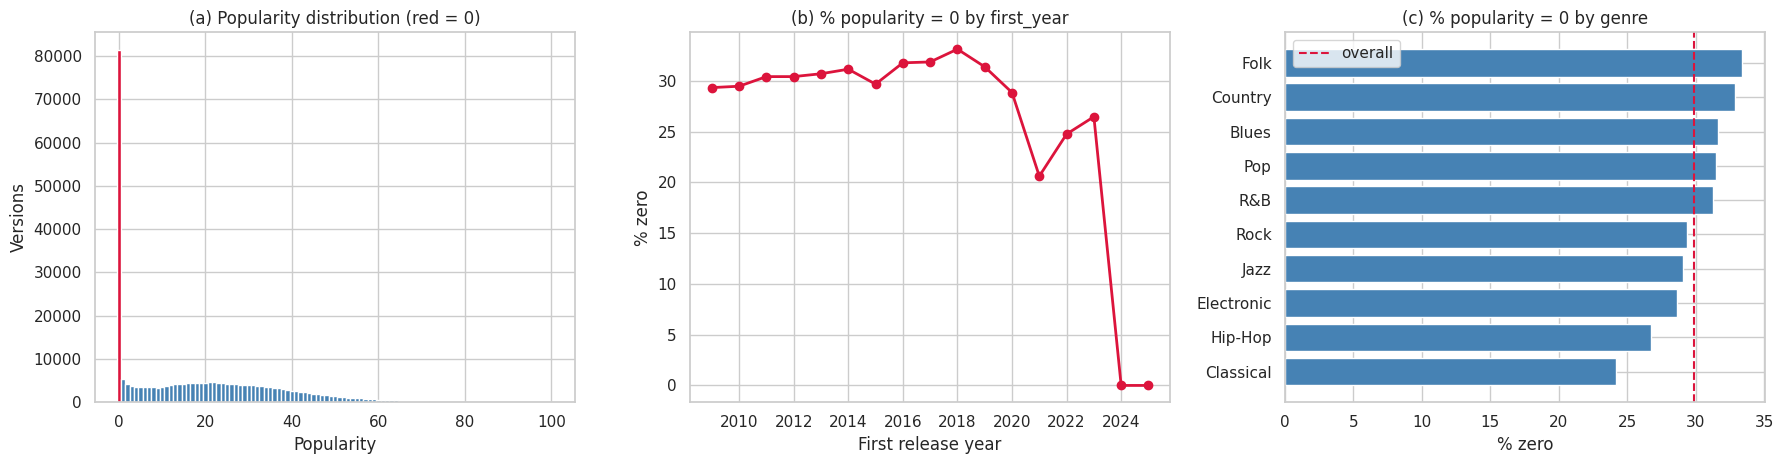

In [ ]:
n_zero = int((df["popularity"] == 0).sum())
zero_share = n_zero / len(df)
pos_keys = set(df.loc[df["popularity"] > 0, "song_key"])
superseded = df.loc[df["popularity"] == 0, "song_key"].isin(pos_keys).mean()
print(f"Versions with popularity = 0: {n_zero:,} rows ({zero_share:.1%} of current data)")
print(f"Versions with popularity = 1–3: {df['popularity'].between(1, 3).sum():,} rows (to check whether 0 is an isolated spike)")
print(f"Zero-popularity versions whose song has another non-zero version (superseded): {superseded:.1%}")
EVIDENCE["zero_pop_pct"] = round(zero_share * 100, 1)
EVIDENCE["zero_superseded_pct"] = round(superseded * 100, 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
pc = df["popularity"].value_counts().reindex(range(0, 101), fill_value=0)
axes[0].bar(pc.index, pc.values, width=1.0, color=[HIGHLIGHT if i == 0 else "steelblue" for i in pc.index])
axes[0].set(title="(a) Popularity distribution (red = 0)", xlabel="Popularity", ylabel="Versions")
zy = df.groupby("first_year")["popularity"].apply(lambda s: (s == 0).mean() * 100)
axes[1].plot(zy.index, zy.values, color=HIGHLIGHT, marker="o", lw=2)
axes[1].set(title="(b) % popularity = 0 by first_year", xlabel="First release year", ylabel="% zero")
zg = df.groupby("genre")["popularity"].apply(lambda s: (s == 0).mean() * 100).sort_values()
axes[2].barh(zg.index, zg.values, color="steelblue")
axes[2].axvline(zero_share * 100, color=HIGHLIGHT, ls="--", label="overall")
axes[2].set(title="(c) % popularity = 0 by genre", xlabel="% zero")
axes[2].legend()
plt.tight_layout()
save_fig("07_zero_popularity")
plt.show()

If `DROP_ZERO_POPULARITY` is `True`, versions with popularity 0 are removed (**Step 6**).

In [ ]:
if CONFIG["DROP_ZERO_POPULARITY"]:
    df = df[df["popularity"] > 0]
    log_step("6. Zero popularity", "mostly delisted / superseded versions; reflects platform status, not the song itself", df, "6. Zero popularity")

[6. Zero popularity] removed 81,447 rows → 191,002 rows remaining


### 2.7 Merging Multiple Versions of the Same Song

Only one row per song is retained.

**Rationale**
1. **Leakage**: if two versions of the same song are assigned to the training and test sets, the model has effectively seen the answer. The risk is higher under a random split than under a split by year (where versions of a song often share the same year), so deduplication must be completed before splitting.
2. **Over-representation**: popular songs tend to have more versions and would otherwise carry excessive weight.

**Which version to keep**

| Rule | Rationale | Risk |
|---|---|---|
| **max_popularity** (default) | Represents the main version that listeners play; lower scores of other versions reflect split plays | Selection based on the target; overall popularity biased upward |
| earliest | The original release; no selection on the target | The original may have been superseded and have a low score |

Both rules are defensible, so the size of the bias is quantified. Both rules are applied to the same multi-version songs and the resulting popularity is compared:
- If the overall mean popularity differs by less than 1 point, the choice has little effect and max_popularity is used.
- If the difference is 1 point or more, a sensitivity analysis with earliest is required and the bias is reported as a limitation.

Ties are broken by `id` with stable sorting, so that re-runs produce identical results.

**Figure**
- **(a)** Popularity of the version retained under each rule (multi-version songs only). Greater separation indicates that the choice of rule matters more.
- **(b)** For the song with the most versions, the year and popularity of each version and the version retained by each rule.

**Note.** If one version of a song has lyrics and another does not, the rule may retain the version without lyrics, and the song becomes `has_lyrics = 0`. The deduplication rule was intentionally left unchanged in v5; this case is recorded as a remaining concern.

[7. Duplicate IDs] removed 0 rows → 191,002 rows remaining
Extra versions of the same song: 19,492 rows (14,182 songs have multiple versions)
Overall mean popularity gap between the two rules: 0.14 points → < 1 point, the choice of rule has little impact
Figure saved: figures/08_dedupe_rule.png


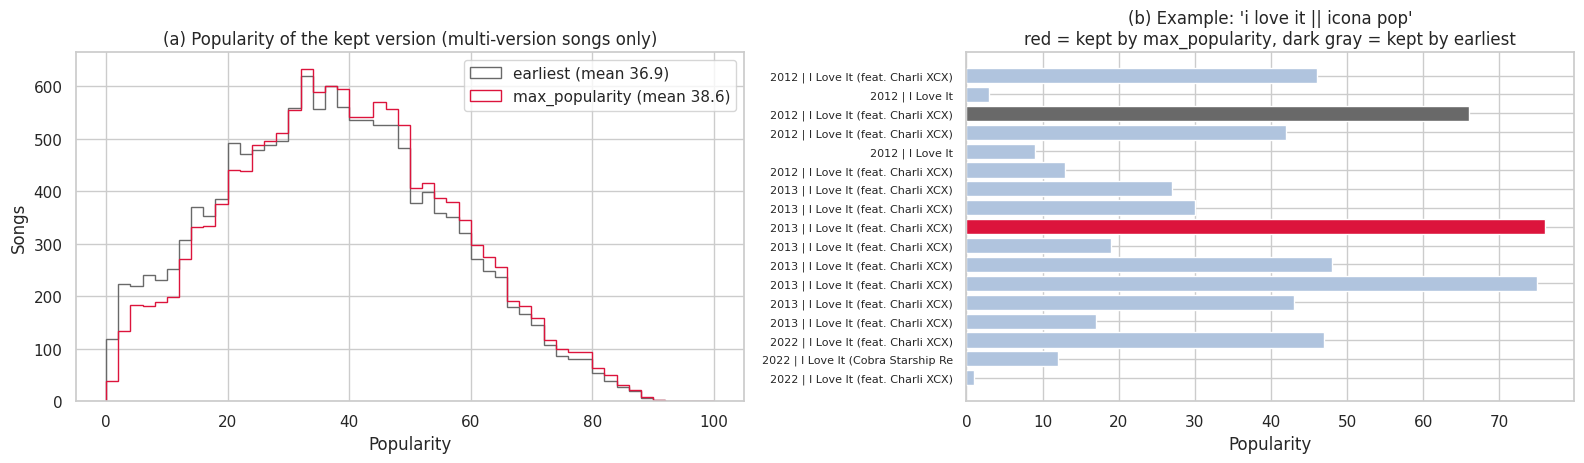

,rule,multi_version_mean_pop,overall_mean_pop,overall_median_pop,chosen
0,max_popularity,38.591,25.986,24.000,yes
1,earliest,36.875,25.844,24.000,


In [ ]:
df = df.drop_duplicates(subset="id", keep="first")
log_step("7. Duplicate IDs", "identical track IDs", df, "7. Duplicate IDs")

RULES = {
    "max_popularity": (["popularity", "year", "id"], [False, True, True]),
    "earliest": (["year", "popularity", "id"], [True, False, True]),
}

def dedupe(data, rule):
    cols, asc = RULES[rule]
    return data.sort_values(cols, ascending=asc, kind="mergesort").drop_duplicates("song_key", keep="first")

multi = df[df.duplicated("song_key", keep=False)]
kept = {r: dedupe(multi, r) for r in RULES}
full = {r: dedupe(df, r) for r in RULES}
print(f"Extra versions of the same song: {df.duplicated('song_key').sum():,} rows ({multi['song_key'].nunique():,} songs have multiple versions)")

dedupe_sensitivity = pd.DataFrame({
    "rule": list(RULES),
    "multi_version_mean_pop": [kept[r]["popularity"].mean() for r in RULES],
    "overall_mean_pop": [full[r]["popularity"].mean() for r in RULES],
    "overall_median_pop": [full[r]["popularity"].median() for r in RULES],
})
dedupe_sensitivity["chosen"] = np.where(dedupe_sensitivity["rule"] == CONFIG["DEDUP_KEEP"], "yes", "")
gap = abs(dedupe_sensitivity["overall_mean_pop"].diff().iloc[-1])
EVIDENCE["dedupe_rule_mean_gap"] = round(gap, 2)
print(f"Overall mean popularity gap between the two rules: {gap:.2f} points → "
      + ("< 1 point, the choice of rule has little impact" if gap < 1 else "≥ 1 point, a sensitivity analysis is required for the final"))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
bins = np.arange(0, 102, 2)
axes[0].hist(kept["earliest"]["popularity"], bins=bins, histtype="step", color="dimgray", lw=2,
             label=f"earliest (mean {kept['earliest']['popularity'].mean():.1f})")
axes[0].hist(kept["max_popularity"]["popularity"], bins=bins, histtype="step", color=HIGHLIGHT, lw=2,
             label=f"max_popularity (mean {kept['max_popularity']['popularity'].mean():.1f})")
axes[0].set(title="(a) Popularity of the kept version (multi-version songs only)", xlabel="Popularity", ylabel="Songs")
axes[0].legend()

if len(multi):
    top_key = multi["song_key"].value_counts().index[0]
    ex = multi[multi["song_key"] == top_key].sort_values(["year", "id"], kind="mergesort")
    keep_max = kept["max_popularity"].loc[kept["max_popularity"]["song_key"] == top_key, "id"].iloc[0]
    keep_early = kept["earliest"].loc[kept["earliest"]["song_key"] == top_key, "id"].iloc[0]
    colors = [HIGHLIGHT if i == keep_max else "dimgray" if i == keep_early else "lightsteelblue" for i in ex["id"]]
    labels = [f"{y} | {str(n)[:28]}" for y, n in zip(ex["year"], ex["name"])]
    axes[1].barh(range(len(ex)), ex["popularity"], color=colors)
    axes[1].set_yticks(range(len(ex)))
    axes[1].set_yticklabels(labels, fontsize=8)
    axes[1].invert_yaxis()
    axes[1].set(title=f"(b) Example: '{top_key[:40]}'\nred = kept by max_popularity, dark gray = kept by earliest", xlabel="Popularity")

plt.tight_layout()
save_fig("08_dedupe_rule")
plt.show()
dedupe_sensitivity

The selected rule (`DEDUP_KEEP`) is applied to the full data, keeping one version per `song_key` (**Step 8**).

In [ ]:
df = dedupe(df, CONFIG["DEDUP_KEEP"])
log_step("8. Merge song versions", f"same song_key → keep rule: {CONFIG['DEDUP_KEEP']}", df, "8. Merge song versions")
EVIDENCE["rows_after_dedupe"] = len(df)

[8. Merge song versions] removed 19,492 rows → 171,510 rows remaining


### 2.8 Lyrics Identity and Duplicate-Lyrics Groups

1. **`lyrics_identity_text`**: an aggressively normalized version of the lyrics used only for duplicate detection.
2. **`lyrics_group_id`**: the SHA-256 hash of `lyrics_identity_text`; lyrics that are identical after normalization share the same group id.
3. In 2.10, all songs with the same `lyrics_group_id` are assigned to the same split.

Covers, remixes, and different performers of the same song have different titles and artists and are not merged by the song identity in 2.7, yet their lyrics are identical. If the original is in the training set and the cover in the test set, the TF-IDF model receives identical input and test performance is inflated.

**Grouping before splitting versus deleting after splitting**

| | v4: delete after splitting | **v5: group before splitting** |
|---|---|---|
| Procedure | Split first, then delete val/test songs whose lyrics match a training song | Build lyrics groups first, then split with groups as the unit |
| Issue | The composition of val/test changes after splitting; which songs are deleted depends on where their duplicates were assigned, so the evaluation sample is conditional | No songs are deleted; each group belongs to one split, so identical lyrics cannot appear in two splits |
| Result | val/test slightly below 15%, with songs that have duplicates under-represented | Proportions may deviate slightly from 70/15/15, but the sample is not filtered after the fact |

**Normalization (`lyrics_identity_text`)**

| Step | Example |
|---|---|
| Unicode NFKC normalization (full-width / half-width and compatibility characters) | `ｌｏｖｅ` → `love` |
| Lowercasing | `I LOVE YOU` → `i love you` |
| Removal of apostrophe variants | `don’t`, `don't` → `dont` |
| Punctuation replaced by spaces | `baby!`, `baby,` → `baby` |
| Line breaks, tabs, and repeated spaces collapsed | Two lines → one line |

Thus `"I love you, baby!\nI love you tonight"` and `"I LOVE YOU baby\nI love you tonight"` map to the same `lyrics_identity_text` and the same `lyrics_group_id`; the next cell tests this example.

SHA-256 is used instead of Python's built-in `hash()`, whose output for strings is randomized between sessions. SHA-256 is deterministic, so group ids are reproducible across sessions and machines; the probability of two different lyrics producing the same hash is negligible.

Songs with `has_lyrics = 0` each form their own group (`nolyrics_` + track id); otherwise all songs without lyrics would be grouped together because their lyrics are empty.

**Scope of the method.** The method detects **formatting-normalized duplicate lyrics**, i.e., lyrics that differ only in case, punctuation, Unicode form, apostrophes, whitespace, or line breaks. It does not detect covers with modified lines, versions with a section removed, translations, or adaptations.

**Possible extension (not implemented).** Near-duplicate lyrics could be detected with MinHash + LSH (estimated Jaccard similarity, e.g., ≥ 0.9) or TF-IDF cosine similarity. A TF-IDF used for duplicate detection would be a preprocessing tool rather than a model feature, and the similarity threshold would need to be validated on manually inspected samples.

**Figure**
- **(a)** Number of songs sharing their lyrics with another song, by exact string match and after normalization; the difference is the number of duplicates missed by v4.
- **(b)** Size distribution of duplicate-lyrics groups (log y-axis).

Normalization test passed: 'i love you baby i love you tonight'
Lyrics fingerprints built (35.7 s)
Songs with lyrics: 171,096 → lyrics groups: 170,065
Exact-string duplicates: 1,388 songs; normalized duplicates: 1,972 songs (584 more found)
Duplicate groups (≥ 2 songs): 941; the largest group has 7 songs
Figure saved: figures/08b_lyrics_groups.png


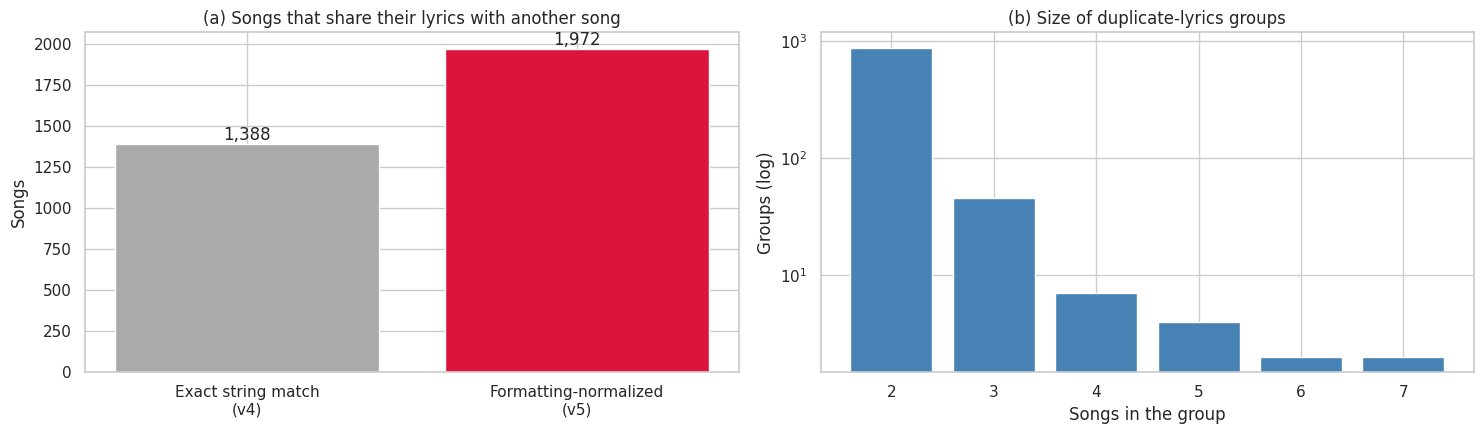


===== Example: different strings, identical after normalization (same lyrics_group_id) =====
  • arctic monkeys — No. 1 Party Anthem: "So you're on the prowl wondering whether\nShe left already or not\nLeather jacket,"
  • exclusion — The Dawn: Chapter 1: "So you're on the prowl wondering whether\nShe left already or not\nLeather jacket,"


In [ ]:
APOS_RE = re.compile(r"[\u2018\u2019\u02bc\u0060\u00b4']")
PUNCT_RE = re.compile(r"[^\w\s]|_")
SPACE_ALL_RE = re.compile(r"\s+")

def lyrics_identity(text):
    t = unicodedata.normalize("NFKC", str(text))
    t = t.lower()
    t = APOS_RE.sub("", t)
    t = PUNCT_RE.sub(" ", t)
    return SPACE_ALL_RE.sub(" ", t).strip()

def stable_text_hash(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

demo_a = "I love you, baby!\nI love you tonight"
demo_b = "I LOVE YOU baby\nI love you tonight"
assert lyrics_identity(demo_a) == lyrics_identity(demo_b), "Normalization did not remove formatting differences!"
assert stable_text_hash(lyrics_identity(demo_a)) == stable_text_hash(lyrics_identity(demo_b)), "SHA-256 mismatch!"
print("Normalization test passed:", repr(lyrics_identity(demo_a)))

t0 = time.time()
df["lyrics_identity_text"] = np.where(df["has_lyrics"] == 1, df["lyrics_model_text"].map(lyrics_identity), "")
df["lyrics_group_id"] = np.where(df["has_lyrics"] == 1,
                                 df["lyrics_identity_text"].map(stable_text_hash),
                                 "nolyrics_" + df["id"].astype(str))
print(f"Lyrics fingerprints built ({time.time() - t0:.1f} s)")

ly = df[df["has_lyrics"] == 1]
exact_dup = ly["lyrics_model_text"].duplicated(keep=False)
ident_dup = ly["lyrics_group_id"].duplicated(keep=False)
gsize = ly["lyrics_group_id"].value_counts()
multi_groups = gsize[gsize > 1]
EVIDENCE["lyric_groups_multi"] = int(len(multi_groups))
EVIDENCE["songs_in_lyric_dup_groups"] = int(ident_dup.sum())
EVIDENCE["extra_dups_found_by_normalization"] = int(ident_dup.sum() - exact_dup.sum())
print(f"Songs with lyrics: {len(ly):,} → lyrics groups: {ly['lyrics_group_id'].nunique():,}")
print(f"Exact-string duplicates: {exact_dup.sum():,} songs; normalized duplicates: {ident_dup.sum():,} songs ({ident_dup.sum() - exact_dup.sum():,} more found)")
print(f"Duplicate groups (≥ 2 songs): {len(multi_groups):,}; the largest group has {int(gsize.max())} songs")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
vals = [int(exact_dup.sum()), int(ident_dup.sum())]
axes[0].bar(["Exact string match\n(v4)", "Formatting-normalized\n(v5)"], vals, color=["#AAAAAA", HIGHLIGHT])
for i, v in enumerate(vals):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")
axes[0].set(title="(a) Songs that share their lyrics with another song", ylabel="Songs")
if len(multi_groups):
    sizes = multi_groups.clip(upper=10).value_counts().sort_index()
    axes[1].bar([str(i) if i < 10 else "10+" for i in sizes.index], sizes.values, color="steelblue")
    axes[1].set_yscale("log")
axes[1].set(title="(b) Size of duplicate-lyrics groups", xlabel="Songs in the group", ylabel="Groups (log)")
plt.tight_layout()
save_fig("08b_lyrics_groups")
plt.show()

extra = ly[ident_dup & ~exact_dup]
if len(extra):
    gid = extra["lyrics_group_id"].iloc[0]
    print("\n===== Example: different strings, identical after normalization (same lyrics_group_id) =====")
    for _, r in ly[ly["lyrics_group_id"] == gid].head(3).iterrows():
        print(f"  • {r['main_artist']} — {r['name']}:", repr(r["lyrics_model_text"][:80]))

### 2.9 Cleaning Log

The rows removed and remaining after each step are summarized in a table and a funnel chart. Each bar shows the rows remaining after a step, with the percentage of the raw data in parentheses; the two largest reductions are highlighted.

The last bar, "9. Lyrics subset", is not a deletion: it shows the restriction from the audio dataset to the lyrics dataset. Songs without valid English lyrics are excluded from the lyrics dataset but remain in the audio dataset.

The two largest reductions, the year filter (scope of the study) and popularity = 0 (platform status), are research-design choices rather than data-quality problems.

[9. Lyrics subset] removed 414 rows → 171,096 rows remaining
Figure saved: figures/09_cleaning_funnel.png


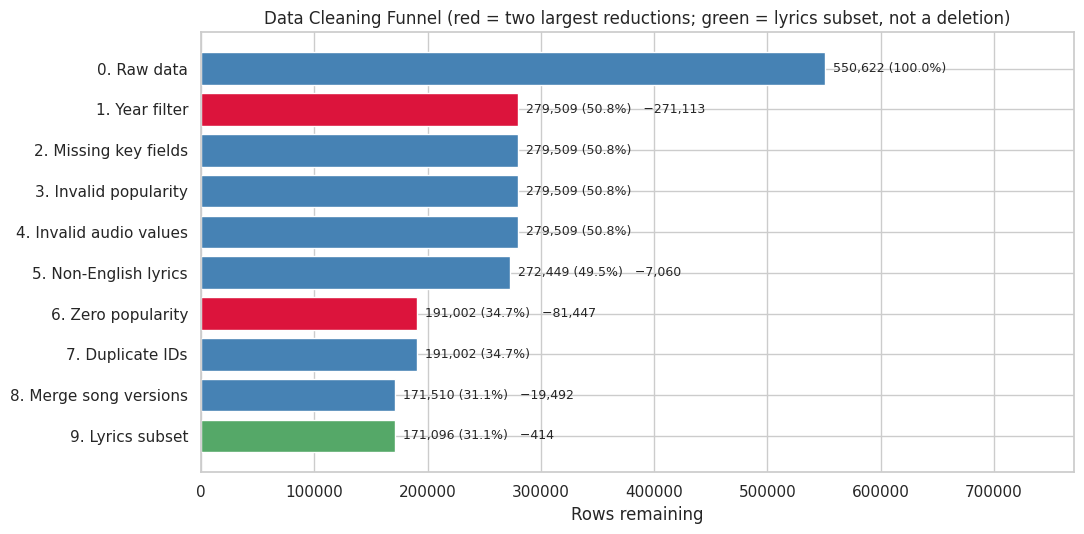

,step,reason,rows_removed,rows_after,pct_of_raw
0,0. Raw data,Kaggle songs.csv,0,550622,100.000
1,1. Year filter,first_year in 2009–2025,271113,279509,50.800
2,2. Missing key fields,missing popularity / year / any of the 9 audio...,0,279509,50.800
3,3. Invalid popularity,popularity outside 0–100,0,279509,50.800
4,4. Invalid audio values,"e.g., tempo = 0 (beat detection failed)",0,279509,50.800
5,5. Non-English lyrics,English stop-word ratio < 0.25 or non-ASCII le...,7060,272449,49.500
6,6. Zero popularity,mostly delisted / superseded versions; reflect...,81447,191002,34.700
7,7. Duplicate IDs,identical track IDs,0,191002,34.700
8,8. Merge song versions,same song_key → keep rule: max_popularity,19492,171510,31.100
9,9. Lyrics subset,songs without valid English lyrics are exclude...,414,171096,31.100


In [ ]:
log_step("9. Lyrics subset", "songs without valid English lyrics are excluded from the lyrics dataset but kept in the audio dataset", df[df["has_lyrics"] == 1], "9. Lyrics subset")

def make_log_df():
    out = pd.DataFrame(cleaning_log)
    out["pct_of_raw"] = (out["rows_after"] / out["rows_after"].iloc[0] * 100).round(1)
    return out

def plot_funnel(log_df):
    fig, ax = plt.subplots(figsize=(11, 5.5))
    biggest = log_df.iloc[:-1]["rows_removed"].nlargest(2).index
    colors = [HIGHLIGHT if i in biggest else ("#55A868" if i == log_df.index[-1] else "steelblue") for i in log_df.index]
    ax.barh(log_df["label_en"], log_df["rows_after"], color=colors)
    ax.invert_yaxis()
    for i, (n, p, r) in enumerate(zip(log_df["rows_after"], log_df["pct_of_raw"], log_df["rows_removed"])):
        txt = f"  {n:,} ({p}%)" + (f"   −{r:,}" if r > 0 else "")
        ax.text(n, i, txt, va="center", fontsize=9)
    ax.set_xlabel("Rows remaining")
    ax.set_title("Data Cleaning Funnel (red = two largest reductions; green = lyrics subset, not a deletion)")
    ax.set_xlim(0, log_df["rows_after"].max() * 1.4)
    plt.tight_layout()
    save_fig("09_cleaning_funnel")
    plt.show()

cleaning_log_df = make_log_df()
plot_funnel(cleaning_log_df)
cleaning_log_df[["step", "reason", "rows_removed", "rows_after", "pct_of_raw"]]

### 2.10 Data Splitting: Primary (Random Stratified) and Robustness (Artist Groups)

Three splits are created and stored in separate columns; `split` takes the method selected by `SPLIT_METHOD` (default: primary).

| Column | Role | Split unit | Stratification | Guarantee |
|---|---|---|---|---|
| **`split_random`** (= `split`) | **Primary analysis (official results)** | Lyrics group `lyrics_group_id` | Era × genre × `has_lyrics` | Identical lyrics appear in only one split; era and genre proportions are nearly identical across splits |
| **`split_artist_group`** | Robustness check | Artist cluster (an artist plus artists sharing identical lyrics) | None | Artist overlap = 0; identical lyrics also appear in only one split |
| `split_temporal` | Robustness check (from v4) | Lyrics group, ordered by the group's earliest `first_year` | Cumulative by year | Older songs in train, newer songs in test |

The split is created before export so that all models use the same split and their results can be reported in one table.

**Primary split (group-wise stratified random split)**
1. Each song has a stratum label, e.g., "2013-2016 | Rock | 1".
2. Each lyrics group is an indivisible unit (most groups contain one song).
3. Within each stratum, groups are randomly ordered (fixed seed) and their song counts accumulated: groups up to 70% of songs go to train, 70–85% to validation, and the remainder to test.

Because groups cannot be divided, the realized proportions may deviate slightly from the targets. Including `has_lyrics` in the stratification ensures that the lyrics dataset (`has_lyrics = 1`) on its own also follows 70/15/15 with the same era and genre proportions. When songs in one group belong to different strata (e.g., the same lyrics released as 2013 Pop and 2019 Rock), the stratum of the first song by id is used; this affects a negligible number of songs.

**Robustness split (artist-group split)**
- All songs by an artist are assigned to exactly one of train, validation, and test.
- If two artists performed identical lyrics (e.g., a cover), they must be assigned together; otherwise identical lyrics would again appear in two splits. Artists and lyrics groups are therefore represented as a bipartite graph, connected **artist clusters** are identified with `connected_components`, and clusters are randomly assigned.
- `GroupShuffleSplit` is not used because its `test_size` refers to the share of groups rather than of songs; with very unequal numbers of songs per artist, song proportions would deviate substantially from 70/15/15. Clusters are instead assigned by accumulating song counts.
- This split is not stratified, so era and genre proportions may differ slightly from the primary split; the figures below quantify the difference.

**Decision rules**
- Preventing leakage takes precedence over exact proportions; deviations below 2 percentage points from the targets are acceptable.
- Primary split: era and genre proportions differ by less than 2 percentage points across splits.
- Artist-group split: artist overlap must be 0.

**Figure**
- **(a)** Song shares under the two splits (target 70/15/15).
- **(b)** Era composition: nearly identical across the three primary splits; possibly different under the artist-group split.
- **(c)** Popularity distributions by split.

Artists: 25,712; artist clusters: 25,340; the largest cluster holds 1.62% of songs
split column uses: random 70/15/15 split, stratified by era × genre × has_lyrics, grouped by lyrics_group_id


,0,1,2,3,4,5
split_method,random (primary),random (primary),artist_group (robustness),artist_group (robustness),temporal (robustness),temporal (robustness)
dataset,all songs (audio dataset),has_lyrics = 1 (lyrics dataset),all songs (audio dataset),has_lyrics = 1 (lyrics dataset),all songs (audio dataset),has_lyrics = 1 (lyrics dataset)
songs_train,120054,119763,120059,119768,118982,118704
pct_train,70.000,70.000,70.000,70.000,69.370,69.380
artists_train,22167,22126,17990,17960,19171,19141
songs_val,25729,25668,25724,25655,14726,14684
pct_val,15.000,15.000,15.000,14.990,8.590,8.580
artists_val,10694,10676,3832,3824,5250,5240
songs_test,25727,25665,25727,25673,37802,37708
pct_test,15.000,15.000,15.000,15.010,22.040,22.040


Figure saved: figures/10_split_primary_vs_artist.png


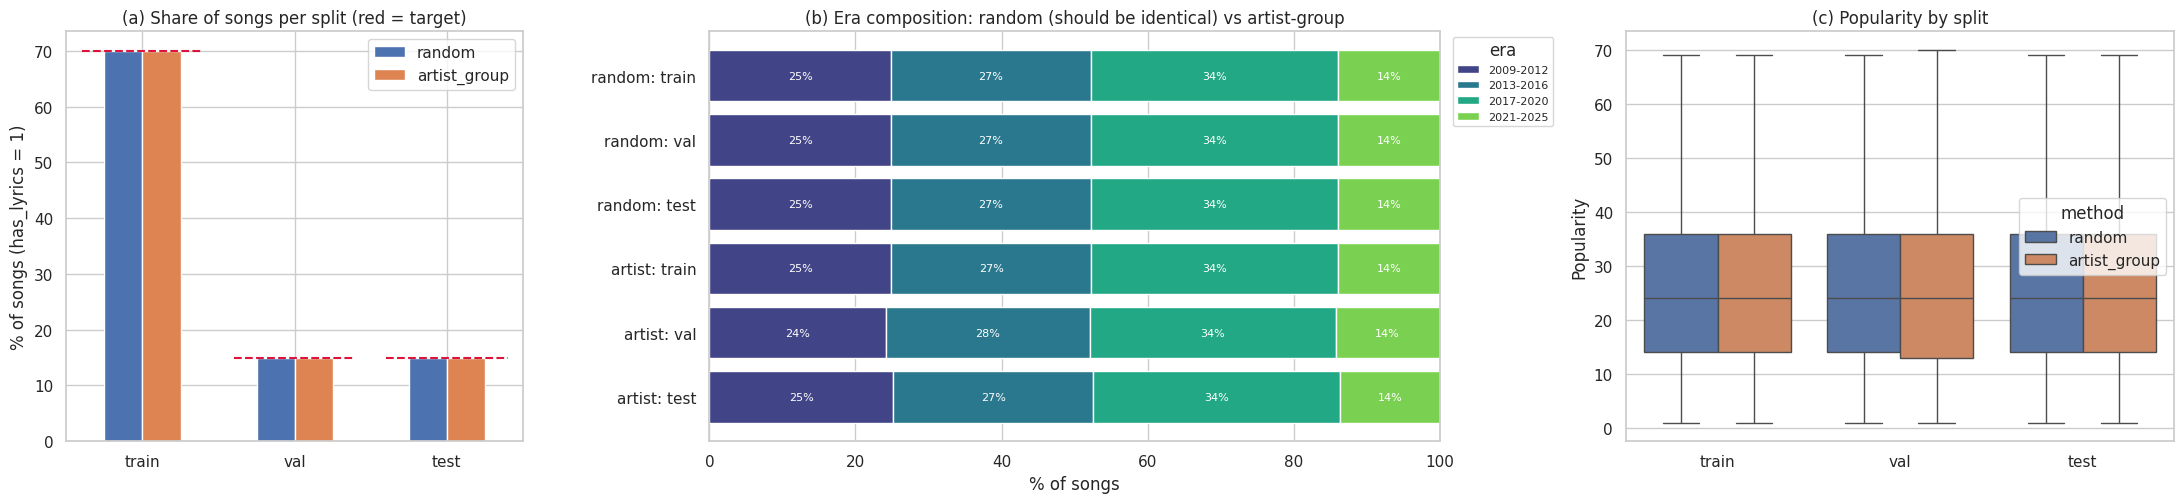

Split checks passed: primary proportions and stratification are correct; artist-group split has artist overlap = 0


In [ ]:
df["era"] = pd.cut(df["first_year"], bins=CONFIG["ERA_BINS"], labels=CONFIG["ERA_LABELS"], right=False).astype(str)
assert (df["era"] != "nan").all(), "Some songs fall outside ERA_BINS! If you change YEAR_MIN / YEAR_MAX, update ERA_BINS too"
TR, VA = CONFIG["TRAIN_RATIO"], CONFIG["VAL_RATIO"]

def group_split(data, group_col, strata_cols, seed):
    g = (data.sort_values("id", kind="mergesort")
             .groupby(group_col, sort=True)
             .agg(n=("id", "size"), **{c: (c, "first") for c in strata_cols}))
    g["stratum"] = g[strata_cols].astype(str).agg(" | ".join, axis=1) if strata_cols else "all"
    g["u"] = np.random.default_rng(seed).random(len(g))
    g = g.sort_values(["stratum", "u"], kind="mergesort")
    pos = (g.groupby("stratum")["n"].cumsum() - g["n"] / 2) / g.groupby("stratum")["n"].transform("sum")
    g["split"] = np.where(pos < TR, "train", np.where(pos < TR + VA, "val", "test"))
    return data[group_col].map(g["split"])

# ===== Primary split: grouped by lyrics_group_id, stratified by era × genre × has_lyrics =====
strata = ["era", "genre", "has_lyrics"] if CONFIG["STRATIFY_GENRE"] else ["era", "has_lyrics"]
df["split_random"] = group_split(df, "lyrics_group_id", strata, RANDOM_STATE)

# ===== Robustness: artist-group split (an artist + artists sharing identical lyrics = one cluster) =====
a_codes, a_names = pd.factorize(df["main_artist"])
g_codes, g_names = pd.factorize(df["lyrics_group_id"])
n_a, n_g = len(a_names), len(g_names)
graph = sparse.coo_matrix((np.ones(len(df)), (a_codes, n_a + g_codes)), shape=(n_a + n_g, n_a + n_g))
n_comp, comp = connected_components(graph, directed=False)
df["artist_cluster"] = comp[a_codes]
df["split_artist_group"] = group_split(df, "artist_cluster", [], RANDOM_STATE)
biggest_cluster_share = df["artist_cluster"].value_counts(normalize=True).iloc[0]
print(f"Artists: {n_a:,}; artist clusters: {df['artist_cluster'].nunique():,}; the largest cluster holds {biggest_cluster_share:.2%} of songs")

# ===== Robustness: temporal split (based on the earliest first_year in each lyrics group) =====
g_year = df.groupby("lyrics_group_id")["first_year"].transform("min")
yr_cum = g_year.value_counts().sort_index().cumsum() / len(df)
tr_years = yr_cum[yr_cum <= TR + 1e-9].index
va_years = yr_cum[(yr_cum > TR + 1e-9) & (yr_cum <= TR + VA + 1e-9)].index
df["split_temporal"] = np.select([g_year.isin(tr_years), g_year.isin(va_years)], ["train", "val"], default="test")

SPLIT_COL = {"random": "split_random", "artist_group": "split_artist_group", "temporal": "split_temporal"}[CONFIG["SPLIT_METHOD"]]
df["split"] = df[SPLIT_COL]
split_method = {"random": "random 70/15/15 split, stratified by era × genre × has_lyrics, grouped by lyrics_group_id",
                "artist_group": "artist-group split (robustness)", "temporal": "temporal split (robustness)"}[CONFIG["SPLIT_METHOD"]]
print("split column uses:", split_method)

def split_diag(data, col):
    out = {}
    share = data[col].value_counts(normalize=True).reindex(SPLIT_ORDER)
    era = pd.crosstab(data[col], data["era"], normalize="index").reindex(SPLIT_ORDER) * 100
    gen = pd.crosstab(data[col], data["genre"], normalize="index").reindex(SPLIT_ORDER) * 100
    arts = {s: set(data.loc[data[col] == s, "main_artist"]) for s in SPLIT_ORDER}
    grp_n_splits = data.groupby("lyrics_group_id")[col].nunique()
    for s in SPLIT_ORDER:
        out[f"songs_{s}"] = int((data[col] == s).sum())
        out[f"pct_{s}"] = round(share[s] * 100, 2)
        out[f"artists_{s}"] = len(arts[s])
    out["artist_overlap_train_val"] = len(arts["train"] & arts["val"])
    out["artist_overlap_train_test"] = len(arts["train"] & arts["test"])
    out["artist_overlap_val_test"] = len(arts["val"] & arts["test"])
    out["lyric_groups_crossing_splits"] = int((grp_n_splits > 1).sum())
    out["max_era_gap_pp"] = round(float((era - era.loc["train"]).abs().max().max()), 2)
    out["max_genre_gap_pp"] = round(float((gen - gen.loc["train"]).abs().max().max()), 2)
    out["pop_mean_train_val_test"] = " / ".join(f"{data.loc[data[col] == s, 'popularity'].mean():.2f}" for s in SPLIT_ORDER)
    return out

diag_rows = []
for name_, col_ in [("random (primary)", "split_random"), ("artist_group (robustness)", "split_artist_group"), ("temporal (robustness)", "split_temporal")]:
    for subset_name, subset in [("all songs (audio dataset)", df), ("has_lyrics = 1 (lyrics dataset)", df[df["has_lyrics"] == 1])]:
        diag_rows.append({"split_method": name_, "dataset": subset_name, **split_diag(subset, col_)})
split_diagnostics = pd.DataFrame(diag_rows)
display(split_diagnostics.T)

lyr = df[df["has_lyrics"] == 1]
fig, axes = plt.subplots(1, 3, figsize=(22, 5.2), gridspec_kw={"width_ratios": [1, 1.6, 1.2]})
shares = pd.DataFrame({m: lyr[c].value_counts(normalize=True).reindex(SPLIT_ORDER) * 100 for m, c in [("random", "split_random"), ("artist_group", "split_artist_group")]})
shares.plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"], rot=0)
for x_, t_ in zip(range(3), [70, 15, 15]):
    axes[0].hlines(t_, x_ - 0.4, x_ + 0.4, color=HIGHLIGHT, ls="--")
axes[0].set(title="(a) Share of songs per split (red = target)", ylabel="% of songs (has_lyrics = 1)", xlabel="")
era_rows = pd.concat({m: pd.crosstab(lyr[c], lyr["era"], normalize="index").reindex(SPLIT_ORDER)[CONFIG["ERA_LABELS"]] * 100
                      for m, c in [("random", "split_random"), ("artist", "split_artist_group")]})
era_rows.index = [f"{m}: {s}" for m, s in era_rows.index]
left = np.zeros(len(era_rows))
for e in CONFIG["ERA_LABELS"]:
    axes[1].barh(era_rows.index, era_rows[e], left=left, color=ERA_COLORS[e], label=e)
    for i, v in enumerate(era_rows[e]):
        if v >= 6:
            axes[1].text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=8)
    left += era_rows[e].values
axes[1].invert_yaxis()
axes[1].set(xlim=(0, 100), xlabel="% of songs", title="(b) Era composition: random (should be identical) vs artist-group")
axes[1].legend(title="era", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
box_df = pd.concat([lyr.assign(method="random", part=lyr["split_random"]), lyr.assign(method="artist_group", part=lyr["split_artist_group"])])
sns.boxplot(data=box_df, x="part", y="popularity", hue="method", order=SPLIT_ORDER, showfliers=False, ax=axes[2], palette=["#4C72B0", "#DD8452"])
axes[2].set(title="(c) Popularity by split", xlabel="", ylabel="Popularity")
plt.tight_layout()
save_fig("10_split_primary_vs_artist")
plt.show()

dg = split_diagnostics.set_index(["split_method", "dataset"])
p_all = dg.loc[("random (primary)", "all songs (audio dataset)")]
p_lyr = dg.loc[("random (primary)", "has_lyrics = 1 (lyrics dataset)")]
a_all = dg.loc[("artist_group (robustness)", "all songs (audio dataset)")]
assert max(abs(p_lyr["pct_train"] - 70), abs(p_lyr["pct_val"] - 15), abs(p_lyr["pct_test"] - 15)) < 2, "Primary split deviates too much from 70/15/15!"
assert p_all["max_era_gap_pp"] < 2 and p_all["max_genre_gap_pp"] < 2, "Era or genre composition differs too much in the primary split!"
assert p_lyr["max_era_gap_pp"] < 2 and p_lyr["max_genre_gap_pp"] < 2, "Era or genre composition differs too much in the lyrics dataset!"
assert a_all["artist_overlap_train_val"] == a_all["artist_overlap_train_test"] == a_all["artist_overlap_val_test"] == 0, "Artist-group split has artist overlap!"
print("Split checks passed: primary proportions and stratification are correct; artist-group split has artist overlap = 0")

EVIDENCE["split_method"] = split_method
EVIDENCE["primary_pct_lyrics"] = f"{p_lyr['pct_train']} / {p_lyr['pct_val']} / {p_lyr['pct_test']}"
EVIDENCE["primary_max_era_gap_pp"] = p_all["max_era_gap_pp"]
EVIDENCE["primary_max_genre_gap_pp"] = p_all["max_genre_gap_pp"]
EVIDENCE["artist_split_pct_lyrics"] = f"{dg.loc[('artist_group (robustness)', 'has_lyrics = 1 (lyrics dataset)'), 'pct_train']} / {dg.loc[('artist_group (robustness)', 'has_lyrics = 1 (lyrics dataset)'), 'pct_val']} / {dg.loc[('artist_group (robustness)', 'has_lyrics = 1 (lyrics dataset)'), 'pct_test']}"
EVIDENCE["artist_split_max_era_gap_pp"] = a_all["max_era_gap_pp"]
EVIDENCE["pop_mean_train_val_test"] = p_lyr["pop_mean_train_val_test"]

### Year and Genre Proportions in the Primary Split

This step verifies in more detail that the primary split (`split_random`) preserves the original year distribution. The objective is equal **proportions** of each year across splits (e.g., if 2020 songs make up 12% of the data, they make up about 12% of each split), not equal numbers of songs per year, which would distort the data.

Equal proportions do not remove the effect of year. Stratification makes the three splits comparable in composition but does not statistically control the relationship between year and popularity; that relationship is examined separately (SQ5, final report).

**Figure**
- **(a)** Share of each `first_year` within each split; the three lines should nearly overlap.
- **(b)** Genre composition of each split; the three bars should be nearly identical.

Figure saved: figures/11_year_genre_by_split.png


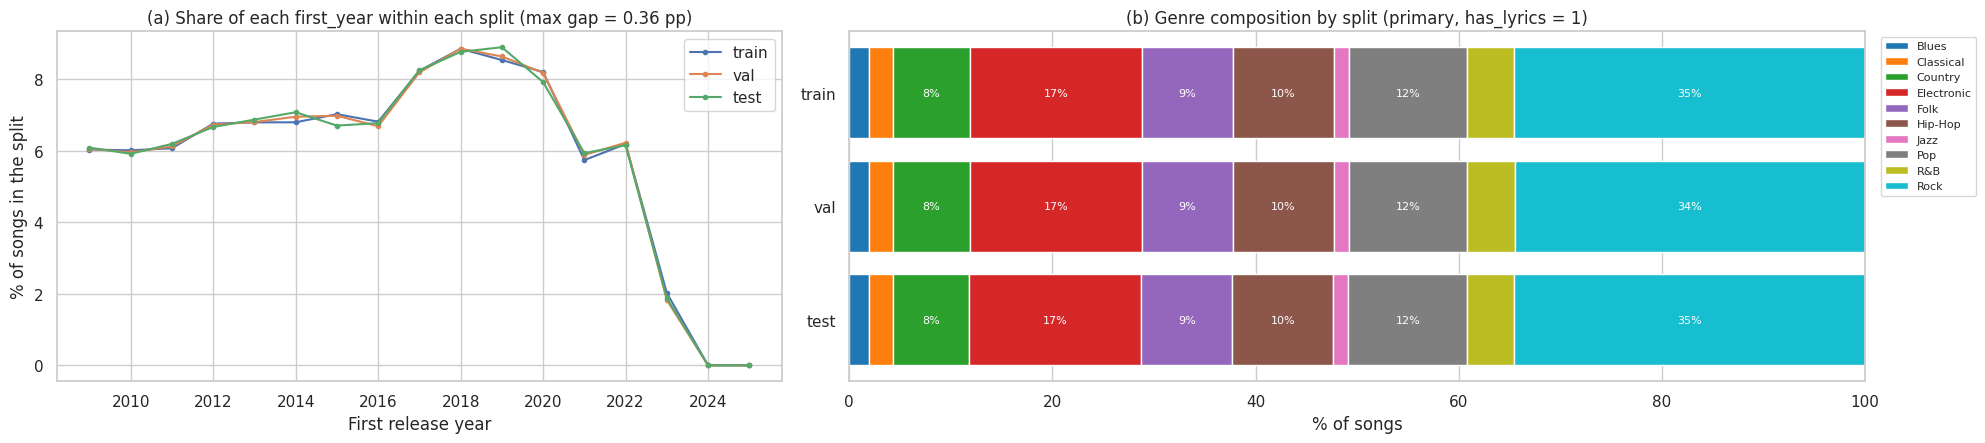

Primary split: max year-share gap across splits = 0.36 pp; max genre gap = 0.04 pp


In [ ]:
lyr = df[df["has_lyrics"] == 1]
yshare = pd.crosstab(lyr["first_year"], lyr["split_random"], normalize="columns")[SPLIT_ORDER] * 100
gshare = (pd.crosstab(lyr["split_random"], lyr["genre"], normalize="index") * 100).reindex(SPLIT_ORDER)
max_year_gap = float((yshare.sub(yshare["train"], axis=0)).abs().max().max())

fig, axes = plt.subplots(1, 2, figsize=(20, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
for s_ in SPLIT_ORDER:
    axes[0].plot(yshare.index, yshare[s_], marker="o", ms=3, color=SPLIT_COLORS[s_], label=s_)
axes[0].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0].set(title=f"(a) Share of each first_year within each split (max gap = {max_year_gap:.2f} pp)", xlabel="First release year", ylabel="% of songs in the split")
axes[0].legend()
left = np.zeros(len(gshare))
palette = sns.color_palette("tab10", n_colors=gshare.shape[1])
for j, g in enumerate(gshare.columns):
    axes[1].barh(gshare.index, gshare[g], left=left, color=palette[j], label=g)
    for i, v in enumerate(gshare[g]):
        if v >= 6:
            axes[1].text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=8)
    left += gshare[g].values
axes[1].invert_yaxis()
axes[1].set(xlim=(0, 100), xlabel="% of songs", title="(b) Genre composition by split (primary, has_lyrics = 1)")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
save_fig("11_year_genre_by_split")
plt.show()
EVIDENCE["primary_max_year_gap_pp"] = round(max_year_gap, 2)
print(f"Primary split: max year-share gap across splits = {max_year_gap:.2f} pp; max genre gap = {float((gshare - gshare.loc['train']).abs().max().max()):.2f} pp")

### 2.11 Leakage Checks: Duplicate-Lyrics Groups and Artist Overlap

**(a) Duplicate-lyrics groups must not cross splits.** Because duplicates are grouped before splitting (2.8, 2.10), no songs are removed here; the check verifies that every `lyrics_group_id` appears in only one split under every split method. Identical lyrics in the training and test sets would allow a TF-IDF model to reproduce the vocabulary pattern of a known lyric and inflate test performance.

**(b) Artist overlap.**
- **Primary split (random)**: artist overlap is retained by design, because new songs often come from artists already observed. The column `artist_seen_in_train` allows error analysis to distinguish seen from unseen artists.
- **Robustness split (artist_group)**: artist overlap must be 0, testing whether the model generalizes to unseen artists.

Under the random split, most artists' songs are spread across all three splits, so artist overlap is high. This is intended but may make results slightly optimistic, which is why the artist-group split is reported alongside.

**Figure**: share of val/test songs whose main artist also appears in the training set, for the primary split (high) and the artist-group split (must be 0).

Lyrics groups crossing splits, by split method: {'split_random': 0, 'split_artist_group': 0, 'split_temporal': 0, 'split': 0}
Figure saved: figures/12_artist_overlap.png


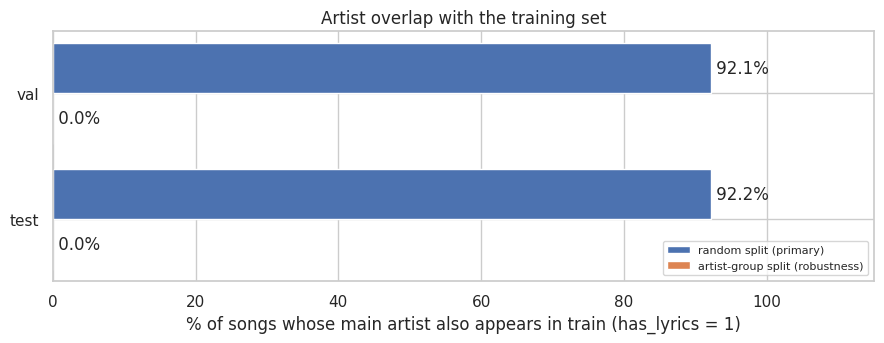

Primary split: val 92.1% / test 92.2% of songs have their main artist in train (kept by design)
Artist-group split: val/test artist overlap = 0% (robustness check)


In [ ]:
crossing = {}
for col_ in ["split_random", "split_artist_group", "split_temporal", "split"]:
    n_cross = int((df.groupby("lyrics_group_id")[col_].nunique() > 1).sum())
    crossing[col_] = n_cross
    assert n_cross == 0, f"{col_}: {n_cross} lyrics groups cross splits!"
print("Lyrics groups crossing splits, by split method:", crossing)
EVIDENCE["lyric_groups_crossing_splits"] = sum(crossing.values())

def artist_overlap(data, col):
    tr_art = set(data.loc[data[col] == "train", "main_artist"])
    return data[data[col] != "train"].groupby(col)["main_artist"].apply(lambda s: s.isin(tr_art).mean()).reindex(["val", "test"])

lyr = df[df["has_lyrics"] == 1]
ov_random = artist_overlap(lyr, "split_random")
ov_artist = artist_overlap(lyr, "split_artist_group")
train_artists = set(df.loc[df["split_random"] == "train", "main_artist"])
df["artist_seen_in_train"] = df["main_artist"].isin(train_artists).astype(int)
assert (ov_artist == 0).all(), "Artist-group split: val/test contains artists from train!"
EVIDENCE["artist_overlap_val_pct"] = round(ov_random["val"] * 100, 1)
EVIDENCE["artist_overlap_test_pct"] = round(ov_random["test"] * 100, 1)

fig, ax = plt.subplots(figsize=(9, 3.6))
yy = np.arange(2)
ax.barh(yy - 0.2, ov_random.values * 100, height=0.4, color="#4C72B0", label="random split (primary)")
ax.barh(yy + 0.2, ov_artist.values * 100, height=0.4, color="#DD8452", label="artist-group split (robustness)")
for i, (a_, b_) in enumerate(zip(ov_random.values * 100, ov_artist.values * 100)):
    ax.text(a_, i - 0.2, f" {a_:.1f}%", va="center")
    ax.text(b_, i + 0.2, f" {b_:.1f}%", va="center")
ax.set_yticks(yy)
ax.set_yticklabels(["val", "test"])
ax.invert_yaxis()
ax.set(xlim=(0, 115), xlabel="% of songs whose main artist also appears in train (has_lyrics = 1)", title="Artist overlap with the training set")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
save_fig("12_artist_overlap")
plt.show()
print(f"Primary split: val {ov_random['val']:.1%} / test {ov_random['test']:.1%} of songs have their main artist in train (kept by design)")
print("Artist-group split: val/test artist overlap = 0% (robustness check)")

### 2.12 Official MAE Baseline: Training-Set Median Popularity

This step computes the **official M0 baseline** and saves it as `results/baseline_reference.csv`, providing a common reference for all models.

M0 predicts the training-set median popularity for every song. Because MAE is the primary evaluation metric, the median is the optimal constant predictor under absolute-error loss: the sum of absolute deviations from a constant is minimized when equally many observations lie on either side of it, which defines the median. The mean minimizes the sum of squared deviations and corresponds to RMSE.

Three baselines are computed, all **from the training set only**; validation and test sets are used only for evaluation.

| Scenario | Data | Split | Use |
|---|---|---|---|
| **Main comparison (official)** | `has_lyrics = 1` | `split_random` | M1 vs M4, M3 |
| Audio supplement | All songs (audio dataset) | `split_random` | Supplementary audio analyses |
| Robustness | `has_lyrics = 1` | `split_artist_group` | Artist-group analysis |

For reference, each scenario also reports the MAE and RMSE of the training-set mean baseline. Under MAE the median baseline is expected to perform better (lower MAE); under RMSE the mean baseline is expected to perform better.

In [ ]:
def baseline_reference(data, split_col, label):
    train_y = data.loc[data[split_col] == "train", "popularity"]
    med, avg = float(train_y.median()), float(train_y.mean())
    rows = []
    for s_ in ["val", "test"]:
        y_ = data.loc[data[split_col] == s_, "popularity"].values
        rows.append({"scenario": label, "split_col": split_col, "eval_on": s_, "n": len(y_),
                     "train_median (official M0)": med, "train_mean (reference)": avg,
                     "MAE_median_baseline": mean_absolute_error(y_, np.full(len(y_), med)),
                     "MAE_mean_baseline": mean_absolute_error(y_, np.full(len(y_), avg)),
                     "RMSE_median_baseline": float(np.sqrt(mean_squared_error(y_, np.full(len(y_), med)))),
                     "RMSE_mean_baseline": float(np.sqrt(mean_squared_error(y_, np.full(len(y_), avg))))})
    return rows

lyr = df[df["has_lyrics"] == 1]
baseline_ref = pd.DataFrame(
    baseline_reference(lyr, "split_random", "PRIMARY: has_lyrics=1, random split (official)")
    + baseline_reference(df, "split_random", "Audio supplement: all songs, random split")
    + baseline_reference(lyr, "split_artist_group", "Robustness: has_lyrics=1, artist-group split"))

official = baseline_ref.iloc[0]
assert np.isclose(official["train_median (official M0)"], lyr.loc[lyr["split_random"] == "train", "popularity"].median()), "The official baseline is not the train median!"
print(f"Official M0 baseline = train median = {official['train_median (official M0)']:.1f} (computed from the {int((lyr['split_random'] == 'train').sum()):,} train songs only)")
for _, r in baseline_ref[baseline_ref["eval_on"] == "test"].iterrows():
    better = "median is better" if r["MAE_median_baseline"] <= r["MAE_mean_baseline"] else "mean is better (unusual, please check)"
    print(f"  {r['scenario']}: test MAE median {r['MAE_median_baseline']:.3f} vs mean {r['MAE_mean_baseline']:.3f} → {better}")
baseline_ref.to_csv(f"{RESULT_DIR}/baseline_reference.csv", index=False)
EVIDENCE["official_baseline_median"] = official["train_median (official M0)"]
EVIDENCE["official_baseline_test_MAE"] = round(float(baseline_ref.iloc[1]["MAE_median_baseline"]), 3)
baseline_ref.round(3)

Official M0 baseline = train median = 24.0 (computed from the 119,763 train songs only)
  PRIMARY: has_lyrics=1, random split (official): test MAE median 12.875 vs mean 12.938 → median is better
  Audio supplement: all songs, random split: test MAE median 12.873 vs mean 12.935 → median is better
  Robustness: has_lyrics=1, artist-group split: test MAE median 12.730 vs mean 12.824 → median is better


,scenario,split_col,eval_on,n,train_median (official M0),train_mean (reference),MAE_median_baseline,MAE_mean_baseline,RMSE_median_baseline,RMSE_mean_baseline
0,"PRIMARY: has_lyrics=1, random split (official)",split_random,val,25668,24.000,25.978,12.931,12.980,16.121,15.994
1,"PRIMARY: has_lyrics=1, random split (official)",split_random,test,25665,24.000,25.978,12.875,12.938,16.086,15.961
2,"Audio supplement: all songs, random split",split_random,val,25729,24.000,25.976,12.928,12.978,16.116,15.990
3,"Audio supplement: all songs, random split",split_random,test,25727,24.000,25.976,12.873,12.935,16.083,15.957
4,"Robustness: has_lyrics=1, artist-group split",split_artist_group,val,25655,24.000,26.033,13.163,13.233,16.425,16.312
5,"Robustness: has_lyrics=1, artist-group split",split_artist_group,test,25673,24.000,26.033,12.730,12.824,15.889,15.783


### 2.13 Export of Two Datasets

The cleaned and split data are saved to `data/`.

| File | Contents |
|---|---|
| `songs_clean.parquet` | **Lyrics dataset**: only `has_lyrics = 1`; includes `lyrics_model_text` and the compatibility column `lyrics_clean` (identical content) |
| `songs_clean.csv` | Lyrics dataset in CSV format (`lyrics_model_text` only) |
| `songs_clean_audio.csv` | **Audio dataset**: all songs (`has_lyrics = 0` and `1`), without full lyrics text; includes `has_lyrics` |
| `results/baseline_reference.csv` | Official baseline values |
| `results/split_diagnostics.csv` | Diagnostics for the three splits |
| `results/cleaning_log.csv`, `data_dictionary.csv`, `sensitivity_*.csv` | Cleaning log, data dictionary, sensitivity tables |

The parquet file includes `lyrics_clean` because Notebook 2 v4 reads that column; it can be removed once Notebook 2 reads `lyrics_model_text`.

The main comparison (audio-only vs audio + lyrics) must use only songs with `has_lyrics == 1` and the same `split` column; songs with `has_lyrics == 0` are used only in supplementary analyses.

Automatic sanity checks run before export; if any check fails, execution stops and no file is written. Rows are sorted by `first_year` and `id` before saving, so that output files are identical across re-runs.

In [ ]:
BASE_COLS = ["id", "name", "artists", "main_artist", "album_name", "year", "first_year", "genre", "popularity"]
SPLIT_COLS = ["split", "split_random", "split_artist_group", "split_temporal", "artist_cluster", "artist_seen_in_train"]
LYRIC_INFO_COLS = ["has_lyrics", "lyrics_n_words", "en_stopword_ratio", "non_ascii_ratio", "lyrics_group_id"]
AUDIO_EXPORT_COLS = ([c for c in BASE_COLS if c in df.columns] + AUDIO_FEATURES
                     + [c for c in LEAKAGE_COLS if c in df.columns] + ["era"] + LYRIC_INFO_COLS + SPLIT_COLS)

df_audio_export = (df[AUDIO_EXPORT_COLS]
                     .sort_values(["first_year", "id"], kind="mergesort")
                     .reset_index(drop=True))
df_export = (df.loc[df["has_lyrics"] == 1, AUDIO_EXPORT_COLS + ["lyrics_model_text"]]
               .sort_values(["first_year", "id"], kind="mergesort")
               .reset_index(drop=True))

for name_, d_ in [("Lyrics dataset", df_export), ("Audio dataset", df_audio_export)]:
    assert d_["id"].is_unique, f"{name_}: duplicate ids!"
    assert d_[["popularity"] + AUDIO_FEATURES].isna().sum().sum() == 0, f"{name_}: missing popularity or audio features!"
    for c_ in ["split", "split_random", "split_artist_group", "split_temporal"]:
        assert d_[c_].isin(SPLIT_ORDER).all(), f"{name_}: invalid values in {c_}!"
    assert d_["era"].isin(CONFIG["ERA_LABELS"]).all(), f"{name_}: some songs have no valid era!"
    for c, (lo, hi) in AUDIO_RANGES.items():
        assert d_[c].between(lo, hi).all(), f"{name_}: {c} has out-of-range values!"
    if CONFIG["DROP_ZERO_POPULARITY"]:
        assert (d_["popularity"] > 0).all(), f"{name_}: songs with popularity = 0 remain!"
assert (df_export["has_lyrics"] == 1).all(), "The lyrics dataset contains songs without lyrics!"
assert not df_export["lyrics_model_text"].str.contains("\\n", regex=False).any(), "Lyrics still contain a literal \\n!"
assert set(df_export["id"]) <= set(df_audio_export["id"]), "Some songs in the lyrics dataset are missing from the audio dataset!"
merged_chk = df_export[["id", "split"]].merge(df_audio_export[["id", "split"]], on="id", suffixes=("_joe", "_bei"))
assert (merged_chk["split_joe"] == merged_chk["split_bei"]).all(), "The same song has different splits in the two datasets!"
print("All sanity checks passed")
print(f"Lyrics dataset: {len(df_export):,} songs; Audio dataset: {len(df_audio_export):,} songs (has_lyrics = 0: {int((df_audio_export['has_lyrics'] == 0).sum()):,})")

All sanity checks passed
Lyrics dataset: 171,096 songs; Audio dataset: 171,510 songs (has_lyrics = 0: 414)


The lyrics dataset is saved as parquet (with the compatibility column `lyrics_clean`) and CSV, the audio dataset as CSV, and the cleaning log, split diagnostics, and sensitivity tables to `results/`. All files are read back and compared with the in-memory data.

In [ ]:
parquet_path = f"{DATA_DIR}/songs_clean.parquet"
clean_path = f"{DATA_DIR}/songs_clean.csv"
audio_path = f"{DATA_DIR}/songs_clean_audio.csv"
df_export.assign(lyrics_clean=df_export["lyrics_model_text"]).to_parquet(parquet_path, index=False)
df_export.to_csv(clean_path, index=False)
df_audio_export.to_csv(audio_path, index=False)
cleaning_log_df.to_csv(f"{RESULT_DIR}/cleaning_log.csv", index=False)
split_diagnostics.to_csv(f"{RESULT_DIR}/split_diagnostics.csv", index=False)
year_sensitivity.to_csv(f"{RESULT_DIR}/sensitivity_year_min.csv", index=False)
words_sensitivity.to_csv(f"{RESULT_DIR}/sensitivity_min_words.csv", index=False)
lang_sensitivity.to_csv(f"{RESULT_DIR}/sensitivity_language_threshold.csv", index=False)
dedupe_sensitivity.to_csv(f"{RESULT_DIR}/sensitivity_dedupe_rule.csv", index=False)

check_pq = pd.read_parquet(parquet_path)
check_audio = pd.read_csv(audio_path, dtype={"id": str})
assert len(check_pq) == len(df_export) and len(check_audio) == len(df_audio_export), "Row counts differ after reading back!"
assert (check_audio["id"].values == df_audio_export["id"].values).all(), "id order differs after reading back!"
assert (check_pq["lyrics_model_text"].values == df_export["lyrics_model_text"].values).all(), "Lyrics in the parquet file differ from the original!"
assert (check_pq["lyrics_clean"].values == check_pq["lyrics_model_text"].values).all(), "Compatibility column lyrics_clean does not match!"
print("Files read back and verified")
for p in [parquet_path, clean_path, audio_path]:
    print(f"   {os.path.basename(p):<26} {os.path.getsize(p) / 1e6:8.1f} MB")

Files read back and verified
   songs_clean.parquet           236.5 MB
   songs_clean.csv               279.7 MB
   songs_clean_audio.csv          55.9 MB


### 2.14 Methodology Sanity Checks

The key checks for the methodological changes in v5 are collected in one table; all must pass before the outputs are used in subsequent notebooks.

| Check | Criterion |
|---|---|
| The official baseline uses the training set only | Median recomputed from train equals the official value |
| Year / era / genre proportions in the primary split | Maximum gap across splits < 2 percentage points |
| Duplicate-lyrics groups do not cross splits | 0 under every split method |
| No artist overlap in the artist-group split | Pairwise overlap = 0 |
| No TF-IDF or scaler fitted before splitting | No fitted `TfidfVectorizer`, `CountVectorizer`, or `StandardScaler` in memory |

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import StandardScaler
fitted_objs = [k for k, v in list(globals().items()) if isinstance(v, (TfidfVectorizer, CountVectorizer, StandardScaler))]
lyr_chk = df[df["has_lyrics"] == 1]
checks = pd.DataFrame([
    ("Median baseline uses train only",
     np.isclose(EVIDENCE["official_baseline_median"], lyr_chk.loc[lyr_chk["split_random"] == "train", "popularity"].median()),
     f"official = train median = {EVIDENCE['official_baseline_median']:.1f}"),
    ("Primary split preserves year / era / genre proportions",
     max(EVIDENCE["primary_max_year_gap_pp"], EVIDENCE["primary_max_era_gap_pp"], EVIDENCE["primary_max_genre_gap_pp"]) < 2,
     f"max gaps (pp): year {EVIDENCE['primary_max_year_gap_pp']}, era {EVIDENCE['primary_max_era_gap_pp']}, genre {EVIDENCE['primary_max_genre_gap_pp']}; shares {EVIDENCE['primary_pct_lyrics']}"),
    ("No normalized lyric group crosses splits",
     EVIDENCE["lyric_groups_crossing_splits"] == 0,
     f"crossing groups (all split methods) = {EVIDENCE['lyric_groups_crossing_splits']}"),
    ("Artist-group split has zero artist overlap",
     bool((artist_overlap(lyr_chk, "split_artist_group") == 0).all()) and bool((artist_overlap(df, "split_artist_group") == 0).all()),
     "val/test artists seen in train = 0% (both datasets)"),
    ("No TF-IDF / scaler fitted in this notebook (fit only on train later)",
     len(fitted_objs) == 0,
     f"objects found: {fitted_objs or 'none'}"),
], columns=["check", "passed", "detail"])
checks["passed"] = checks["passed"].map({True: "PASS", False: "FAIL"})
checks.to_csv(f"{RESULT_DIR}/methodology_sanity_checks.csv", index=False)
assert (checks["passed"] == "PASS").all(), "Some methodology checks failed; see the table above!"
pd.set_option("display.max_colwidth", 160)
checks

,check,passed,detail
0,Median baseline uses train only,PASS,official = train median = 24.0
1,Primary split preserves year / era / genre proportions,PASS,"max gaps (pp): year 0.36, era 0.04, genre 0.04; shares 70.0 / 15.0 / 15.0"
2,No normalized lyric group crosses splits,PASS,crossing groups (all split methods) = 0
3,Artist-group split has zero artist overlap,PASS,val/test artists seen in train = 0% (both datasets)
4,No TF-IDF / scaler fitted in this notebook (fit only on train later),PASS,objects found: none
